# TC3 — Fluxo unificado com metas e rastreabilidade por escola/ano

Cópia evolutiva do fluxo validado. Mantém as 18 features não constantes do contrato atualizado e
preserva `id_escola` e `chave_escola_ano` exclusivamente como chaves técnicas.
Nenhuma das duas entra no treinamento.


## 1. Premissas e decisões metodológicas

- Unidade analítica: uma observação de aluno por ano de referência.
- Integração das fontes externas: município, ano e UF.
- `id_escola` é anonimizado e não corresponde a `CO_ENTIDADE` ou `ID_ESCOLA`; não é usado para relacionar as fontes.
- INSE e Censo Escolar foram agregados ao nível municipal antes da integração.
- As colunas `in_*` provenientes do Censo representam proporções municipais de escolas com o recurso, apesar do nome herdado da fonte.
- Variáveis ligadas à aplicação da avaliação ou à construção do target são excluídas das features.
- Imputações são estimadas exclusivamente no conjunto de treino indicado por `dataset_split`.
- Identificadores são preservados somente para rastreabilidade.
- `chave_escola_ano` combina ano, município e identificador anônimo para agrupar alunos na mesma edição.
- A chave não identifica a escola real, não relaciona Censo/INSE e não rastreia a mesma unidade entre anos.


### Linhagem das fontes

| Fonte | Granularidade original | Tratamento no TC3-82 | Uso neste fluxo |
|---|---|---|---|
| `ml_aluno` | Aluno/ano | Base principal | Target, tempo, UF, rede e controles |
| Bolsa Família | Município/ano | Join municipal anual | Contexto financeiro transformado |
| Fundeb | Município/ano | Join municipal anual | Contexto financeiro transformado, preservando sinal |
| Receitas | Município/ano | Join municipal anual | Contexto financeiro transformado |
| PIB | Município/ano | Join municipal anual | PIB per capita de 2023 como fotografia contextual |
| INSE | Escola | Agregação ponderada por município/ano | Média INSE de 2023 como fotografia contextual |
| Censo Escolar | Escola | Agregação por município/ano | Proporções municipais de infraestrutura de 2023 |

A reconstrução das fontes brutas permanece no TC3-82. Este notebook começa na camada consolidada, verifica seu contrato e produz a camada final de modelagem.


## Inicialização independente

Esta célula reproduz a configuração compartilhada do notebook principal. Ela prepara ambiente, caminhos e funções comuns sem alterar a lógica canônica desta etapa.


In [1]:
# =============================================================================
# CONFIGURAÇÕES PARA RODAR O NOTEBOOK
# Execute esta célula primeiro. Esta política não altera a metodologia do fluxo.
# =============================================================================
import os
import sys
import gc
import ctypes
import polars as pl
from datetime import datetime, timezone

# Opções do usuário
PERFIL_RECURSOS = "auto"       # auto | baixo | medio | normal | alto
LIMITE_RAM_PERCENTUAL = None    # None = automático; ou inteiro entre 50 e 90
MAX_THREADS = None              # None = automático; ou inteiro >= 1
USAR_GPU = os.getenv("TC3_USAR_GPU", "1").strip().lower() in {"1", "true", "sim", "yes"}                 # requer WSL2 + RAPIDS/cuML + kernel tc3-gpu

REUTILIZAR_ARTEFATOS = False  # False reconstrói; True aceita caches válidos
SALVAR_ARTEFATOS = True       # False usa somente área temporária da sessão


# Protocolo metodologico compartilhado por todas as fases e modelos.
SEED_GLOBAL = 42
EXECUTAR_SHAP = os.getenv("TC3_EXECUTAR_SHAP", "0").strip().lower() in {"1", "true", "sim", "yes"}
AMOSTRA_SHAP = max(20, int(os.getenv("TC3_AMOSTRA_SHAP", "100")))
AMOSTRA_BACKGROUND_SHAP = max(20, int(os.getenv("TC3_BACKGROUND_SHAP", "50")))
CHAVE_GRUPO_GLOBAL = "chave_escola_ano"
N_SPLITS_CV_GLOBAL = 3
N_ITER_BUSCA_GLOBAL = 10
LIMIAR_CLASSIFICACAO_GLOBAL = 0.50
REPETICOES_PERMUTACAO_GLOBAL = 5
REPETICOES_BOOTSTRAP_GLOBAL = 200

N_JOBS_MODELAGEM_GLOBAL = 1
N_SPLITS_HOLDOUT_GLOBAL = 1
SCORING_PRINCIPAL_GLOBAL = "roc_auc"
VERBOSE_BUSCA_GLOBAL = 2
ERRO_BUSCA_GLOBAL = "raise"
RETORNAR_SCORE_TREINO_GLOBAL = True

# Contrato comum de pre-processamento dos modelos.
IMPUTACAO_NUMERICA_GLOBAL = "median"
IMPUTACAO_CATEGORICA_GLOBAL = "most_frequent"
ONE_HOT_DESCONHECIDO_GLOBAL = "ignore"
ONE_HOT_SPARSO_GLOBAL = False  # matriz densa: evita fallback dos modelos para CPU
SPARSE_THRESHOLD_GLOBAL = 0.0
ESCALONADOR_CENTRALIZAR_GLOBAL = False


# Percentuais de amostragem (0 < valor <= 1). Alterar aqui afeta todo o notebook.
# O teste final permanece integral (100%); as amostras menores servem apenas ao
# desenvolvimento, comparacao de modelos e interpretabilidade.
FRACOES_AMOSTRAGEM = {
    "eda_correlacao": 0.05,
    "validacao_preparacao": 0.02,
    "fase5_modelos": 0.10,
    "fase5_knn": 0.02,  # KNN tem custo de memoria e predicao maior.
    "fase6_desenvolvimento": 0.12,
    "fase6_validacao_interna": 0.25,
    "fase7_desenvolvimento": 1.00,
    "fase7_teste": 1.00,
    "interpretacao": 0.035,
    "bootstrap": 0.17,
}

for _nome, _fracao in FRACOES_AMOSTRAGEM.items():
    if not 0 < _fracao <= 1:
        raise ValueError(f"Fracao invalida em FRACOES_AMOSTRAGEM[{_nome!r}]: {_fracao}")


def tamanho_por_fracao(total, fracao):
    """Converte uma proporcao em quantidade reproduzivel, sem exceder o total."""
    if total < 1:
        raise ValueError("Nao e possivel amostrar uma particao vazia.")
    return min(total, max(1, round(total * fracao)))


def materializar_split_percentual(dados, contrato, nome_split, fracao, seed, materializador):
    """Materializa uma fracao de um split e informa claramente o universo usado."""
    import polars as pl

    coluna_split = contrato["controle_split"]
    total = (
        dados.filter(pl.col(coluna_split) == nome_split)
        .select(pl.len().alias("total"))
        .collect()
        .item()
    )
    quantidade = tamanho_por_fracao(total, fracao)
    X, y = materializador(dados, contrato, nome_split, limit=quantidade, seed=seed)
    print(f"{nome_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return X, y


def _estado_memoria_sistema():
    """Retorna RAM total e disponível em bytes."""
    valores = {}
    try:
        with open("/proc/meminfo", encoding="utf-8") as arquivo:
            for linha in arquivo:
                chave, valor = linha.split(":", 1)
                valores[chave] = int(valor.strip().split()[0]) * 1024
        return valores["MemTotal"], valores.get("MemAvailable", valores.get("MemFree", 0))
    except (OSError, KeyError, ValueError):
        try:
            return (
                os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
                os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
            )
        except (AttributeError, OSError, ValueError):
            return None, None


RAM_TOTAL_BYTES, RAM_DISPONIVEL_BYTES = _estado_memoria_sistema()
RAM_TOTAL_GB = RAM_TOTAL_BYTES / 1024**3 if RAM_TOTAL_BYTES else 0.0
CPUS_LOGICAS = os.cpu_count() or 1

if RAM_TOTAL_GB and RAM_TOTAL_GB <= 4.5:
    _perfil_detectado = "baixo"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 8.5:
    _perfil_detectado = "medio"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 16.5:
    _perfil_detectado = "normal"
else:
    _perfil_detectado = "alto"

_perfis = {
    "baixo": (60, 1),
    "medio": (70, min(2, CPUS_LOGICAS)),
    "normal": (75, min(4, CPUS_LOGICAS)),
    "alto": (80, min(8, max(1, CPUS_LOGICAS // 2))),
}
PERFIL_ATIVO = _perfil_detectado if PERFIL_RECURSOS == "auto" else PERFIL_RECURSOS.lower()
if PERFIL_ATIVO not in _perfis:
    raise ValueError("PERFIL_RECURSOS deve ser auto, baixo, medio, normal ou alto.")

_limite_perfil, _threads_perfil = _perfis[PERFIL_ATIVO]
LIMITE_RAM_ATIVO = _limite_perfil if LIMITE_RAM_PERCENTUAL is None else int(LIMITE_RAM_PERCENTUAL)
THREADS_MAXIMAS = _threads_perfil if MAX_THREADS is None else int(MAX_THREADS)
if not 50 <= LIMITE_RAM_ATIVO <= 90:
    raise ValueError("LIMITE_RAM_PERCENTUAL deve ficar entre 50 e 90.")
if THREADS_MAXIMAS < 1:
    raise ValueError("MAX_THREADS deve ser pelo menos 1.")
THREADS_MAXIMAS = min(THREADS_MAXIMAS, CPUS_LOGICAS)

# Definido antes de NumPy, Polars, scikit-learn e cuML serem importados.
for _variavel, _valor in {
    "OMP_NUM_THREADS": str(THREADS_MAXIMAS),
    "OPENBLAS_NUM_THREADS": str(THREADS_MAXIMAS),
    "MKL_NUM_THREADS": str(THREADS_MAXIMAS),
    "NUMEXPR_NUM_THREADS": str(THREADS_MAXIMAS),
    "VECLIB_MAXIMUM_THREADS": str(THREADS_MAXIMAS),
    "POLARS_MAX_THREADS": str(THREADS_MAXIMAS),
    "MALLOC_ARENA_MAX": "2",
}.items():
    os.environ[_variavel] = _valor

HISTORICO_RECURSOS = []
_estado_recursos = {"nivel": None, "threads": None, "contexto_threads": None}


def _aplicar_threads(limite):
    """Limita pools BLAS/OpenMP já carregados; Polars usa o limite inicial."""
    limite = max(1, min(int(limite), THREADS_MAXIMAS))
    if _estado_recursos["threads"] == limite:
        return
    anterior = _estado_recursos.get("contexto_threads")
    if anterior is not None:
        try:
            anterior.__exit__(None, None, None)
        except Exception:
            pass
    try:
        from threadpoolctl import threadpool_limits
        contexto = threadpool_limits(limits=limite)
        contexto.__enter__()
    except Exception:
        contexto = None
    _estado_recursos["contexto_threads"] = contexto
    _estado_recursos["threads"] = limite


def _liberar_memoria_global(agressiva=False):
    """Libera caches transitórios sem apagar variáveis usadas pelo fluxo."""
    shell = get_ipython()
    if shell is not None:
        for nome in ("_", "__", "___"):
            shell.user_ns[nome] = None
    gc.collect()
    modulo_cupy = sys.modules.get("cupy")
    if modulo_cupy is not None:
        try:
            modulo_cupy.get_default_memory_pool().free_all_blocks()
            modulo_cupy.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
    if agressiva:
        modulo_plt = sys.modules.get("matplotlib.pyplot")
        if modulo_plt is not None:
            try:
                modulo_plt.close("all")
            except Exception:
                pass
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except (OSError, AttributeError):
            pass


def _gerenciar_recursos(*_args, **_kwargs):
    """Reduz paralelismo progressivamente e nunca interrompe uma célula."""
    total, disponivel = _estado_memoria_sistema()
    if not total:
        return
    uso = 100.0 * (total - disponivel) / total
    margem = LIMITE_RAM_ATIVO - uso
    if margem > 15:
        nivel, threads, limpar = "normal", THREADS_MAXIMAS, False
    elif margem > 7:
        nivel, threads, limpar = "moderado", max(1, THREADS_MAXIMAS // 2), True
    else:
        nivel, threads, limpar = "conservador", 1, True

    _aplicar_threads(threads)
    if limpar:
        _liberar_memoria_global(agressiva=margem <= 0)

    if nivel != _estado_recursos["nivel"]:
        registro = {
            "instante_utc": datetime.now(timezone.utc).isoformat(),
            "nivel": nivel,
            "threads": threads,
            "ram_usada_percentual": round(uso, 1),
            "ram_disponivel_gb": round(disponivel / 1024**3, 2),
        }
        HISTORICO_RECURSOS.append(registro)
        print(
            f"[recursos] nível={nivel}; threads={threads}; "
            f"RAM usada={uso:.1f}%; livre={disponivel / 1024**3:.1f} GB."
        )
        _estado_recursos["nivel"] = nivel


ipython = get_ipython()
if ipython is not None:
    # Impede callbacks duplicados ao reexecutar a configuração.
    for _atributo in ("_tc3_memory_guard", "_tc3_resource_guard"):
        _guard_anterior = getattr(ipython, _atributo, None)
        if _guard_anterior is not None:
            for _evento, _funcao in _guard_anterior:
                try:
                    ipython.events.unregister(_evento, _funcao)
                except (ValueError, KeyError):
                    pass
    _callbacks_recursos = [
        ("pre_run_cell", _gerenciar_recursos),
        ("post_run_cell", _gerenciar_recursos),
    ]
    for _evento, _funcao in _callbacks_recursos:
        ipython.events.register(_evento, _funcao)
    ipython._tc3_resource_guard = _callbacks_recursos

_gerenciar_recursos()
print(
    "Configuração automática ativa: "
    f"perfil={PERFIL_ATIVO}; RAM={RAM_TOTAL_GB:.1f} GB; CPUs={CPUS_LOGICAS}; "
    f"limite preventivo={LIMITE_RAM_ATIVO}%; threads máximas={THREADS_MAXIMAS}."
)

# Backend GPU: ativado antes de qualquer importação do scikit-learn.
cuda_conda = os.path.join(sys.prefix, "targets", "x86_64-linux")
if os.path.exists(os.path.join(cuda_conda, "include", "cuda.h")):
    os.environ.setdefault("CUDA_PATH", cuda_conda)
if USAR_GPU:
    try:
        from cuml.accel import install
        install(log_level="info")
        import cupy as cp
        dispositivo = cp.cuda.runtime.getDeviceProperties(0)
        nome_gpu = dispositivo["name"].decode() if isinstance(dispositivo["name"], bytes) else str(dispositivo["name"])
        memoria_gpu_gb = cp.cuda.runtime.memGetInfo()[1] / 1024**3
        BACKEND_ML = f"RAPIDS cuML — {nome_gpu} ({memoria_gpu_gb:.1f} GB de VRAM)"
    except Exception as exc:
        raise RuntimeError("GPU/RAPIDS indisponível. Abra no WSL2 e selecione o kernel tc3-gpu.") from exc
else:
    BACKEND_ML = "scikit-learn CPU"
print("Backend de Machine Learning:", BACKEND_ML)

from pathlib import Path
import hashlib
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def localizar_raiz(inicio: Path) -> Path:
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "dados").is_dir() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Execute este notebook dentro do repositório tech_challenge_3.")

PROJECT_ROOT = localizar_raiz(Path.cwd().resolve())
print("Raiz do projeto:", PROJECT_ROOT)


# Contrato único de diretórios. Fontes sempre são lidas da área imutável.
import tempfile

FONTES_ORIGINAIS_DIR = PROJECT_ROOT / "dados" / "fontes_originais"
_TEMP_BASE = PROJECT_ROOT / ".execucao_temporaria"
_TEMP_BASE.mkdir(parents=True, exist_ok=True)
if SALVAR_ARTEFATOS:
    RAIZ_ARTEFATOS = PROJECT_ROOT
    _DIRETORIO_TEMPORARIO = None
else:
    _DIRETORIO_TEMPORARIO = tempfile.TemporaryDirectory(prefix="tc3_", dir=_TEMP_BASE)
    RAIZ_ARTEFATOS = Path(_DIRETORIO_TEMPORARIO.name)

DADOS_PROCESSADOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_processados"
DADOS_ANALITICOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_analiticos"
RESULTADOS_DIR = RAIZ_ARTEFATOS / "resultados"
RESULTADOS_FIGURAS_DIR = RESULTADOS_DIR / "figuras"
RESULTADOS_TABELAS_DIR = RESULTADOS_DIR / "tabelas"
RESULTADOS_METRICAS_DIR = RESULTADOS_DIR / "metricas"
RESULTADOS_RELATORIOS_DIR = RESULTADOS_DIR / "relatorios"
MODELOS_DIR = RAIZ_ARTEFATOS / "modelos"

for _diretorio_saida in (
    DADOS_PROCESSADOS_DIR, DADOS_ANALITICOS_DIR, RESULTADOS_FIGURAS_DIR,
    RESULTADOS_TABELAS_DIR, RESULTADOS_METRICAS_DIR,
    RESULTADOS_RELATORIOS_DIR, MODELOS_DIR,
):
    _diretorio_saida.mkdir(parents=True, exist_ok=True)

def deve_recalcular(caminho):
    """True quando o cache deve ser ignorado ou ainda não existe."""
    return not REUTILIZAR_ARTEFATOS or not Path(caminho).exists()


def publicar_parquet_particionado(frame, destino, *, particionar_por):
    """Publica partições sequencialmente e troca o diretório de forma atômica.

    O ``write_parquet(partition_by=...)`` do Polars prepara várias partições em
    paralelo e pode duplicar o pico de RAM de bases já materializadas. Esta
    implementação mantém apenas uma partição adicional em memória por vez.
    """
    import gc
    import shutil

    destino = Path(destino)
    temporario = destino.with_name(destino.name + "__publicacao_tmp")
    anterior = destino.with_name(destino.name + "__publicacao_anterior")
    for caminho in (temporario, anterior):
        if caminho.exists():
            shutil.rmtree(caminho)
    temporario.mkdir(parents=True, exist_ok=True)

    lazy = frame if isinstance(frame, pl.LazyFrame) else frame.lazy()
    schema = lazy.collect_schema()
    if particionar_por not in schema.names():
        raise ValueError(f"Coluna de particionamento ausente: {particionar_por}")

    valores = (
        lazy.select(pl.col(particionar_por).unique())
        .collect(engine="streaming")
        .get_column(particionar_por)
        .to_list()
    )
    valores = sorted(valores, key=lambda valor: (valor is None, str(valor)))
    if not valores:
        raise RuntimeError("Não há valores para particionar a publicação.")

    arquivos_novos = []
    for indice, valor in enumerate(valores):
        valor_hive = "__HIVE_DEFAULT_PARTITION__" if valor is None else str(valor)
        if any(separador in valor_hive for separador in ("/", "\\")):
            raise ValueError(f"Valor de partição inválido: {valor_hive!r}")
        diretorio_particao = temporario / f"{particionar_por}={valor_hive}"
        diretorio_particao.mkdir(parents=True, exist_ok=True)
        arquivo = diretorio_particao / f"part-{indice:05d}.parquet"
        predicado = pl.col(particionar_por).is_null() if valor is None else pl.col(particionar_por) == pl.lit(valor)
        lazy.filter(predicado).sink_parquet(
            arquivo,
            compression="zstd",
            statistics=True,
            row_group_size=100_000,
            mkdir=True,
            engine="streaming",
        )
        if not arquivo.is_file() or arquivo.stat().st_size == 0:
            raise RuntimeError(f"Partição não foi gravada corretamente: {arquivo}")
        arquivos_novos.append(arquivo)
        gc.collect()

    if destino.exists():
        destino.replace(anterior)
    try:
        try:
            temporario.replace(destino)
        except OSError:
            # Volumes Docker montados do Windows podem bloquear rename de diretórios.
            # O fallback copia a publicação pronta e remove a área temporária.
            shutil.copytree(temporario, destino)
            shutil.rmtree(temporario)
    except Exception:
        if destino.exists():
            shutil.rmtree(destino)
        if anterior.exists():
            anterior.replace(destino)
        raise
    if anterior.exists():
        shutil.rmtree(anterior)
    return len(arquivos_novos)


def salvar_figura_eda(figura, nome):
    """Exporta uma figura exploratória sem alterar sua exibição no notebook."""
    destino = RESULTADOS_FIGURAS_DIR / "fluxo_exploratorio" / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino, dpi=180, bbox_inches="tight")
    return destino

print("Fontes originais:", FONTES_ORIGINAIS_DIR)
print("Destino dos artefatos:", RAIZ_ARTEFATOS)
print("Reutilizar artefatos:", REUTILIZAR_ARTEFATOS, "| Salvar:", SALVAR_ARTEFATOS)

# Imports compartilhados que, no fluxo completo, são carregados por etapas anteriores.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


[recursos] nível=normal; threads=4; RAM usada=31.0%; livre=10.7 GB.
Configuração automática ativa: perfil=normal; RAM=15.5 GB; CPUs=20; limite preventivo=75%; threads máximas=4.
[cuml.accel] Accelerator installed.
Backend de Machine Learning: RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)
Raiz do projeto: /workspace
Fontes originais: /workspace/dados/fontes_originais
Destino dos artefatos: /workspace
Reutilizar artefatos: False | Salvar: True


In [2]:
from pathlib import Path
import json
import math
import polars as pl
import matplotlib.pyplot as plt


pl.Config.set_tbl_rows(100)
pl.Config.set_tbl_cols(100)
plt.style.use("seaborn-v0_8-whitegrid")


In [3]:
# PROJECT_ROOT e herdado da configuracao central.
INPUT_DIR = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"
OUTPUT_DIR = DADOS_PROCESSADOS_DIR / "preparado" / "base_modelagem_final_com_chave_escola_por_uf"
DECISION_PATH = RESULTADOS_TABELAS_DIR / "dicionario_dados" / "decisoes_features_modelagem_com_chave_escola.csv"
DATA_DICTIONARY_PATH = RESULTADOS_TABELAS_DIR / "dicionario_dados" / "base_modelagem_catalogo_com_chave_escola.csv"

arquivos = sorted(INPUT_DIR.glob("sigla_uf=*/*.parquet"))
if not arquivos:
    raise FileNotFoundError(f"Nenhum Parquet localizado em {INPUT_DIR}")

lf = pl.scan_parquet([str(p) for p in arquivos], hive_partitioning=True)
schema = lf.collect_schema()
print(f"Raiz: {PROJECT_ROOT}")
print(f"Partições/arquivos: {len(arquivos)}")
print(f"Colunas: {len(schema)}")


Raiz: /workspace
Partições/arquivos: 26
Colunas: 49


## 2. Contrato de variáveis

A seleção abaixo substitui as decisões preliminares baseadas apenas nas 19 colunas originais. O contrato diferencia features, chaves, controles, target e exclusões.


In [4]:
TARGET = "alfabetizado"
SOURCE_KEY_COLUMNS = ["id_aluno", "id_municipio", "id_escola"]
KEY_COLUMNS = SOURCE_KEY_COLUMNS + ["chave_escola_ano"]
CONTROL_COLUMNS = ["dataset_split"]
CATEGORICAL_FEATURES = ["sigla_uf", "rede"]
NUMERIC_FEATURES = [
    "ano_referencia",
    "taxa_alfabetizacao_municipio_ano_anterior",
    "media_portugues_municipio_ano_anterior",
    "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
    "valor_pib", "valor_pib_per_capita",
    "qtd_escolas_inse", "qtd_alunos_inse", "media_inse",
    "pc_nivel_1", "pc_nivel_2", "pc_nivel_3", "pc_nivel_4",
    "pc_nivel_5", "pc_nivel_6", "pc_nivel_7", "pc_nivel_8",
    "qtd_escolas_censo", "qt_mat_bas", "qt_doc_bas", "qt_tur_bas",
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica",
    "in_quadra_esportes", "in_agua_rede_publica",
    "in_energia_rede_publica", "in_esgoto_rede_publica",
    "in_internet", "in_banda_larga",
]
LEAKAGE_COLUMNS = ["proficiencia", "presenca", "preenchimento_caderno", "caderno"]
EXCLUDED_NETWORKS = {4: "Privada — 25 registros de uma única escola/município"}
TECHNICAL_COLUMNS = ["processed_at", "peso_aluno"]
REDUNDANT_COLUMNS = ["nome_municipio", "rede_descricao", "serie", "nome uf", "nome do município"]

# Conjunto enxuto definido após o EDA. Os demais campos numéricos acima continuam
# disponíveis somente para análise e documentação das exclusões.
STATIC_2023_FEATURES = [
    "valor_pib_per_capita", "media_inse",
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica",
    "in_quadra_esportes", "in_agua_rede_publica",
    "in_energia_rede_publica", "in_esgoto_rede_publica",
    "in_internet", "in_banda_larga",
]
CURRENT_FINANCIAL_FEATURES = ["valor_bolsa_familia", "valor_fundeb", "valor_receitas"]
FINAL_SOURCE_FEATURES = ["ano_referencia"] + CURRENT_FINANCIAL_FEATURES + STATIC_2023_FEATURES
FINAL_MODEL_FEATURES = (
    CATEGORICAL_FEATURES + ["ano_referencia"]
    + [f"{c}__signed_log1p" for c in CURRENT_FINANCIAL_FEATURES + ["valor_pib_per_capita"]]
    + ["media_inse"]
    + [c for c in STATIC_2023_FEATURES if c.startswith("in_")]
    + ["cobertura_financeira_ausente", "cobertura_inse_ausente"]
)
FEATURES = FINAL_MODEL_FEATURES
required = set(SOURCE_KEY_COLUMNS + CONTROL_COLUMNS + CATEGORICAL_FEATURES + FINAL_SOURCE_FEATURES + [TARGET])
missing_required = sorted(required - set(schema.names()))
if missing_required:
    raise KeyError(f"Colunas necessárias ausentes: {missing_required}")

print(f"Features finais aprovadas: {len(FEATURES)}")
print(f"Chaves de rastreabilidade: {KEY_COLUMNS}")
print(f"Excluídas por leakage: {LEAKAGE_COLUMNS}")


Features finais aprovadas: 18
Chaves de rastreabilidade: ['id_aluno', 'id_municipio', 'id_escola', 'chave_escola_ano']
Excluídas por leakage: ['proficiencia', 'presenca', 'preenchimento_caderno', 'caderno']


In [5]:
motivos = {
    TARGET: ("target", "Variável-alvo; nunca entra nas features."),
    **{c: ("chave", "Mantida apenas para rastreabilidade e validação.") for c in KEY_COLUMNS},
    **{c: ("controle", "Controla a separação dos dados; não entra no modelo.") for c in CONTROL_COLUMNS},
    **{c: ("feature_categorica", "Contexto disponível; encoding será ajustado no pipeline do modelo.") for c in CATEGORICAL_FEATURES},
    **{c: ("feature_numerica_final", "Indicador mantido no conjunto final; pode ser transformado antes da persistência.") for c in FINAL_SOURCE_FEATURES},
    **{c: ("excluir_pos_eda", "Removida após o EDA por redundância, cobertura temporal inadequada ou representação equivalente mais enxuta.") for c in set(NUMERIC_FEATURES) - set(FINAL_SOURCE_FEATURES)},
    **{c: ("excluir_leakage", "Ligada à aplicação da avaliação ou à construção/mensuração do target.") for c in LEAKAGE_COLUMNS},
    **{c: ("excluir_tecnica", "Campo técnico ou peso amostral; não representa característica preditiva.") for c in TECHNICAL_COLUMNS},
    **{c: ("excluir_redundante", "Identificador de alta cardinalidade, constante ou representação redundante.") for c in REDUNDANT_COLUMNS},
}
motivos["rede"] = ("feature_categorica", "Somente redes estadual (2) e municipal (3); a rede privada (4) é excluída antes da modelagem por conter apenas 25 registros de uma única escola/município.")
decisoes = pl.DataFrame([
    {"coluna": c, "decisao": motivos.get(c, ("revisar", "Não classificada no contrato."))[0],
     "justificativa": motivos.get(c, ("revisar", "Não classificada no contrato."))[1]}
    for c in schema.names()
]).sort(["decisao", "coluna"])
display(decisoes)

nao_classificadas = decisoes.filter(pl.col("decisao") == "revisar")
assert nao_classificadas.is_empty(), f"Há colunas sem decisão: {nao_classificadas['coluna'].to_list()}"


coluna,decisao,justificativa
str,str,str
"""id_aluno""","""chave""","""Mantida apenas para rastreabil…"
"""id_escola""","""chave""","""Mantida apenas para rastreabil…"
"""id_municipio""","""chave""","""Mantida apenas para rastreabil…"
"""dataset_split""","""controle""","""Controla a separação dos dados…"
"""caderno""","""excluir_leakage""","""Ligada à aplicação da avaliaçã…"
"""preenchimento_caderno""","""excluir_leakage""","""Ligada à aplicação da avaliaçã…"
"""presenca""","""excluir_leakage""","""Ligada à aplicação da avaliaçã…"
"""proficiencia""","""excluir_leakage""","""Ligada à aplicação da avaliaçã…"
"""media_portugues_municipio_ano_…","""excluir_pos_eda""","""Removida após o EDA por redund…"


## 3. Auditoria estrutural e qualidade

As verificações abaixo substituem suposições por testes executáveis: esquema das partições, volume, granularidade, duplicidades, nulos e distribuição do target.


In [6]:
schemas_particoes = []
for arquivo in arquivos:
    nomes = pl.scan_parquet(arquivo).collect_schema().names()
    schemas_particoes.append({"arquivo": str(arquivo.relative_to(PROJECT_ROOT)), "colunas": nomes})

schema_referencia = schemas_particoes[0]["colunas"]
divergentes = [x["arquivo"] for x in schemas_particoes if x["colunas"] != schema_referencia]
assert not divergentes, f"Partições com esquema divergente: {divergentes}"

resumo_estrutura = lf.select(
    pl.len().alias("registros"),
    pl.col("id_aluno").n_unique().alias("alunos_distintos"),
    pl.col("id_municipio").n_unique().alias("municipios_distintos"),
    pl.col("sigla_uf").n_unique().alias("ufs_distintas"),
    pl.col("ano_referencia").min().alias("ano_min"),
    pl.col("ano_referencia").max().alias("ano_max"),
).collect()
display(resumo_estrutura)
print("Todas as partições têm o mesmo esquema.")


registros,alunos_distintos,municipios_distintos,ufs_distintas,ano_min,ano_max
u32,u32,u32,u32,i64,i64
3867999,2352328,5548,26,2023,2024


Todas as partições têm o mesmo esquema.


In [7]:
duplicatas_aluno_ano = (
    lf.group_by(["id_aluno", "ano_referencia"])
      .agg(pl.len().alias("quantidade"))
      .filter(pl.col("quantidade") > 1)
      .select(pl.len().alias("chaves_duplicadas"))
      .collect()
)
display(duplicatas_aluno_ano)
assert duplicatas_aluno_ano.item() == 0, "Existem duplicatas por aluno/ano."


chaves_duplicadas
u32
0


In [8]:
# O projeto trabalha exclusivamente com a 2ª série.
series_observadas = lf.select(pl.col("serie").drop_nulls().unique().sort()).collect()["serie"].to_list()
assert series_observadas == [2], f"Recorte inesperado de série: {series_observadas}"
print("Recorte de série validado:", series_observadas)

# O mesmo aluno não pode aparecer em mais de um split, mesmo quando ocorre nos dois anos.
alunos_multiplos_splits = (
    lf.group_by("id_aluno")
      .agg(pl.col("dataset_split").n_unique().alias("quantidade_splits"))
      .filter(pl.col("quantidade_splits") > 1)
      .select(pl.len().alias("alunos_em_multiplos_splits"))
      .collect()
)
display(alunos_multiplos_splits)
assert alunos_multiplos_splits.item() == 0, "Há alunos compartilhados entre os splits."

distribuicao_split = lf.group_by("dataset_split").agg(
    pl.len().alias("registros"),
    pl.col("id_aluno").n_unique().alias("alunos_distintos"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).sort("dataset_split").collect()
display(distribuicao_split)


Recorte de série validado: [2]


alunos_em_multiplos_splits
u32
0


dataset_split,registros,alunos_distintos,proporcao_alfabetizado
str,u32,u32,f64
"""teste""",581596,353855,0.513601
"""treino""",2705252,1645229,0.513002
"""validacao""",581151,353244,0.512841


**Limite do identificador:** a ausência de alunos compartilhados entre splits protege a avaliação. Ainda assim, `id_aluno` é anonimizado e não deve ser usado para inferir mobilidade entre municípios nem trajetórias individuais entre anos.


In [9]:
total = lf.select(pl.len()).collect().item()
nulos = (
    lf.select([pl.col(c).null_count().alias(c) for c in schema.names()])
      .collect()
      .unpivot(variable_name="coluna", value_name="nulos")
      .with_columns((100 * pl.col("nulos") / total).round(2).alias("percentual_nulos"))
      .sort("percentual_nulos", descending=True)
)
display(nulos)


coluna,nulos,percentual_nulos
str,u32,f64
"""taxa_alfabetizacao_municipio_a…",1791646,46.32
"""media_portugues_municipio_ano_…",1791646,46.32
"""proficiencia""",513338,13.27
"""peso_aluno""",513338,13.27
"""valor_receitas""",34500,0.89
"""valor_fundeb""",33712,0.87
"""qtd_escolas_inse""",2330,0.06
"""qtd_alunos_inse""",2330,0.06
"""media_inse""",2330,0.06


## 4. EDA consolidada

A EDA é executada sobre a base consolidada, mas as conclusões e os tratamentos são vinculados ao contrato de variáveis. Não são criadas regras a partir dos conjuntos de validação ou teste.


alfabetizado,quantidade,percentual
i32,u32,f64
0,1883453,48.69
1,1984546,51.31


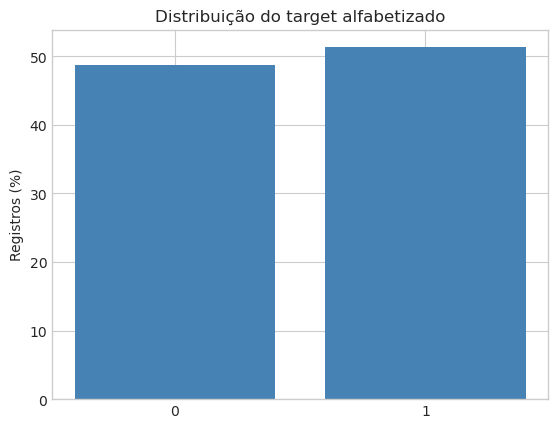

In [10]:
distribuicao_target = (
    lf.group_by(TARGET)
      .agg(pl.len().alias("quantidade"))
      .with_columns((100 * pl.col("quantidade") / pl.col("quantidade").sum()).round(2).alias("percentual"))
      .sort(TARGET)
      .collect()
)
display(distribuicao_target)
target_plot = distribuicao_target
plt.bar(target_plot[TARGET].cast(pl.String).to_list(), target_plot["percentual"].to_numpy(), color="steelblue")
plt.title("Distribuição do target alfabetizado")
plt.ylabel("Registros (%)")
salvar_figura_eda(plt.gcf(), "286_4_eda_consolidada_01.png"); plt.show()


In [11]:
cobertura_temporal = (
    lf.group_by("ano_referencia")
      .agg(
          pl.len().alias("registros"),
          *[pl.col(c).is_not_null().mean().round(4).alias(f"cobertura__{c}") for c in NUMERIC_FEATURES if c != "ano_referencia"]
      )
      .sort("ano_referencia")
      .collect()
)
display(cobertura_temporal)


ano_referencia,registros,cobertura__taxa_alfabetizacao_municipio_ano_anterior,cobertura__media_portugues_municipio_ano_anterior,cobertura__valor_bolsa_familia,cobertura__valor_fundeb,cobertura__valor_receitas,cobertura__valor_pib,cobertura__valor_pib_per_capita,cobertura__qtd_escolas_inse,cobertura__qtd_alunos_inse,cobertura__media_inse,cobertura__pc_nivel_1,cobertura__pc_nivel_2,cobertura__pc_nivel_3,cobertura__pc_nivel_4,cobertura__pc_nivel_5,cobertura__pc_nivel_6,cobertura__pc_nivel_7,cobertura__pc_nivel_8,cobertura__qtd_escolas_censo,cobertura__qt_mat_bas,cobertura__qt_doc_bas,cobertura__qt_tur_bas,cobertura__in_biblioteca_sala_leitura,cobertura__in_laboratorio_informatica,cobertura__in_quadra_esportes,cobertura__in_agua_rede_publica,cobertura__in_energia_rede_publica,cobertura__in_esgoto_rede_publica,cobertura__in_internet,cobertura__in_banda_larga
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2023,1747439,0.0,0.0,1.0,0.9983,0.9985,1.0,1.0,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,0.9993,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2024,2120560,0.9792,0.9792,1.0,0.9855,0.9849,1.0,1.0,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [12]:
numericas_eda = [c for c in NUMERIC_FEATURES if c != "ano_referencia"]

# Estatísticas descritivas e quantis exigem materialização. Para evitar que essa
# etapa exploratória esgote a RAM, usamos amostra determinística e limitada pelo
# perfil detectado. Contagens oficiais continuam sendo calculadas integralmente
# nas células anteriores.
limites_eda_por_perfil = {
    "baixo": 50_000,
    "medio": 100_000,
    "normal": 200_000,
    "alto": 300_000,
}
limite_linhas_eda = limites_eda_por_perfil[PERFIL_ATIVO]
fracao_eda = min(FRACOES_AMOSTRAGEM["eda_correlacao"], limite_linhas_eda / max(total, 1))
limite_hash_eda = max(1, round(fracao_eda * 10_000))

amostra_numerica_eda = (
    lf.filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL) % 10_000) < limite_hash_eda)
      .select(numericas_eda)
      .head(limite_linhas_eda)
      .collect(engine="streaming")
)
print(
    f"Resumo numérico: {amostra_numerica_eda.height:,}/{total:,} registros "
    f"({amostra_numerica_eda.height / max(total, 1):.2%}); perfil={PERFIL_ATIVO}."
)
resumo_numerico = amostra_numerica_eda.describe()
display(resumo_numerico)

del amostra_numerica_eda
_liberar_memoria_global(agressiva=True)


Resumo numérico: 192,850/3,867,999 registros (4.99%); perfil=normal.


statistic,taxa_alfabetizacao_municipio_ano_anterior,media_portugues_municipio_ano_anterior,valor_bolsa_familia,valor_fundeb,valor_receitas,valor_pib,valor_pib_per_capita,qtd_escolas_inse,qtd_alunos_inse,media_inse,pc_nivel_1,pc_nivel_2,pc_nivel_3,pc_nivel_4,pc_nivel_5,pc_nivel_6,pc_nivel_7,pc_nivel_8,qtd_escolas_censo,qt_mat_bas,qt_doc_bas,qt_tur_bas,in_biblioteca_sala_leitura,in_laboratorio_informatica,in_quadra_esportes,in_agua_rede_publica,in_energia_rede_publica,in_esgoto_rede_publica,in_internet,in_banda_larga
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",103684.0,103684.0,192850.0,191184.0,191168.0,192850.0,192850.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192727.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0,192850.0
"""null_count""",89166.0,89166.0,0.0,1666.0,1682.0,0.0,0.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,123.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",56.262114,744.985233,4.6570e8,-6.7873e8,5.2915e10,5.9418e10,50193.647384,156.357589,24155.687236,4.919099,1.508505,13.005624,17.267879,21.948456,20.585448,14.515737,10.104855,1.063503,586.620109,183800.990397,10659.156801,8155.795266,0.589698,0.340704,0.432514,0.818846,0.981923,0.624323,0.946107,0.877071
"""std""",15.373921,19.625143,1.0908e9,9.2326e9,1.7838e11,1.8723e11,50540.261463,339.25219,63393.449998,0.428919,2.20288,11.091847,7.468014,4.183394,6.13878,7.567246,7.256687,0.934085,1535.243235,484563.311889,28276.264494,21975.310209,0.202798,0.162344,0.171892,0.236753,0.080417,0.341691,0.12404,0.149915
"""min""",3.41,673.2983,45671.0,-4.5338e10,8.3986e6,2.1017664e7,6757.48,1.0,15.0,3.504799,0.0,0.0,0.0,3.262136,2.713333,0.0,0.0,0.0,2.0,183.0,15.0,14.0,0.0,0.0,0.0,0.0,0.063492,0.0,0.047619,0.0
"""25%""",46.56,733.5938,2.1213354e7,-1.2144e7,1.3348e9,7.83841e8,23203.21,13.0,1059.0,4.555143,0.221307,4.223407,10.761524,19.211454,15.402391,7.374293,3.50074,0.338464,38.0,6924.0,451.0,342.0,0.454545,0.230137,0.333333,0.740469,0.993915,0.338028,0.964286,0.824493
"""50%""",55.62,742.7747,7.0022127e7,1.4180e8,4.5886e9,4.1387e9,39993.15,36.0,3578.0,4.998492,0.574672,8.293117,16.450475,22.51141,22.483609,15.039165,8.858812,0.863381,100.0,24869.0,1471.0,1122.0,0.625,0.351145,0.458824,0.928571,1.0,0.72,0.993105,0.930818
"""75%""",65.74,753.1549,2.53392656e8,6.9188e8,1.9224e10,2.2791e10,63192.47,108.0,14066.0,5.270837,2.000339,20.88724,24.400391,25.219683,25.365505,20.729098,15.396681,1.578969,327.0,96373.0,5873.0,4246.0,0.743083,0.440341,0.555556,0.991597,1.0,0.939394,1.0,0.976923
"""max""",100.0,868.4554,5.2370e9,3.5589e10,2.5756e12,1.0668e12,842004.6,1677.0,356802.0,5.940142,41.774715,58.557768,40.247683,40.819,48.24,40.368571,50.835156,11.292616,8449.0,2.670096e6,155496.0,122981.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [13]:
categorias = []
for coluna in CATEGORICAL_FEATURES + ["ano_referencia", "dataset_split"]:
    tabela = (
        lf.group_by(coluna).agg(pl.len().alias("quantidade"))
          .with_columns((100 * pl.col("quantidade") / pl.col("quantidade").sum()).round(2).alias("percentual"))
          .sort("quantidade", descending=True).collect()
    )
    print(f"\n{coluna}")
    display(tabela)



sigla_uf


sigla_uf,quantidade,percentual
str,u32,f64
"""SP""",443777,11.47
"""MG""",413557,10.69
"""RJ""",311198,8.05
"""PR""",277446,7.17
"""BA""",253300,6.55
"""RS""",229410,5.93
"""PA""",204949,5.3
"""SC""",201171,5.2
"""CE""",190190,4.92



rede


rede,quantidade,percentual
i32,u32,f64
3,3432576,88.74
2,435398,11.26
4,25,0.0



ano_referencia


ano_referencia,quantidade,percentual
i64,u32,f64
2024,2120560,54.82
2023,1747439,45.18



dataset_split


dataset_split,quantidade,percentual
str,u32,f64
"""treino""",2705252,69.94
"""teste""",581596,15.04
"""validacao""",581151,15.02


In [14]:
# Categorias raras são registradas para tratamento no pipeline, sem alterar a semântica da base.
MIN_CATEGORIA_TREINO = 1_000
categorias_raras = (
    lf.filter(pl.col("dataset_split") == "treino")
      .group_by("rede").agg(pl.len().alias("registros_treino"))
      .filter(pl.col("registros_treino") < MIN_CATEGORIA_TREINO)
      .sort("registros_treino")
      .collect()
)
display(categorias_raras)
print("Categorias raras exigem decisão explícita de escopo ou tratamento; a decisão aplicada consta na seção 5.")


rede,registros_treino
i32,u32
4,16


Categorias raras exigem decisão explícita de escopo ou tratamento; a decisão aplicada consta na seção 5.


In [15]:
# Correlações são triagem descritiva; não comprovam causalidade.
corr_target = lf.select([
    pl.corr(pl.col(c).cast(pl.Float64), pl.col(TARGET).cast(pl.Float64)).alias(c)
    for c in numericas_eda
]).collect().unpivot(variable_name="feature", value_name="correlacao_target")
corr_target = corr_target.with_columns(pl.col("correlacao_target").abs().alias("abs_correlacao")).sort("abs_correlacao", descending=True)
display(corr_target)


feature,correlacao_target,abs_correlacao
str,f64,f64
"""media_portugues_municipio_ano_…",0.246996,0.246996
"""taxa_alfabetizacao_municipio_a…",0.235955,0.235955
"""in_laboratorio_informatica""",0.069195,0.069195
"""in_quadra_esportes""",0.059441,0.059441
"""in_biblioteca_sala_leitura""",0.057111,0.057111
"""in_internet""",0.050351,0.050351
"""pc_nivel_3""",-0.047412,0.047412
"""pc_nivel_7""",0.04513,0.04513
"""pc_nivel_6""",0.044552,0.044552


### 4.1 Distribuições e assimetria

As visualizações usam uma amostra reprodutível para evitar materializar milhões de pontos. As estatísticas descritivas anteriores continuam calculadas sobre a base completa.


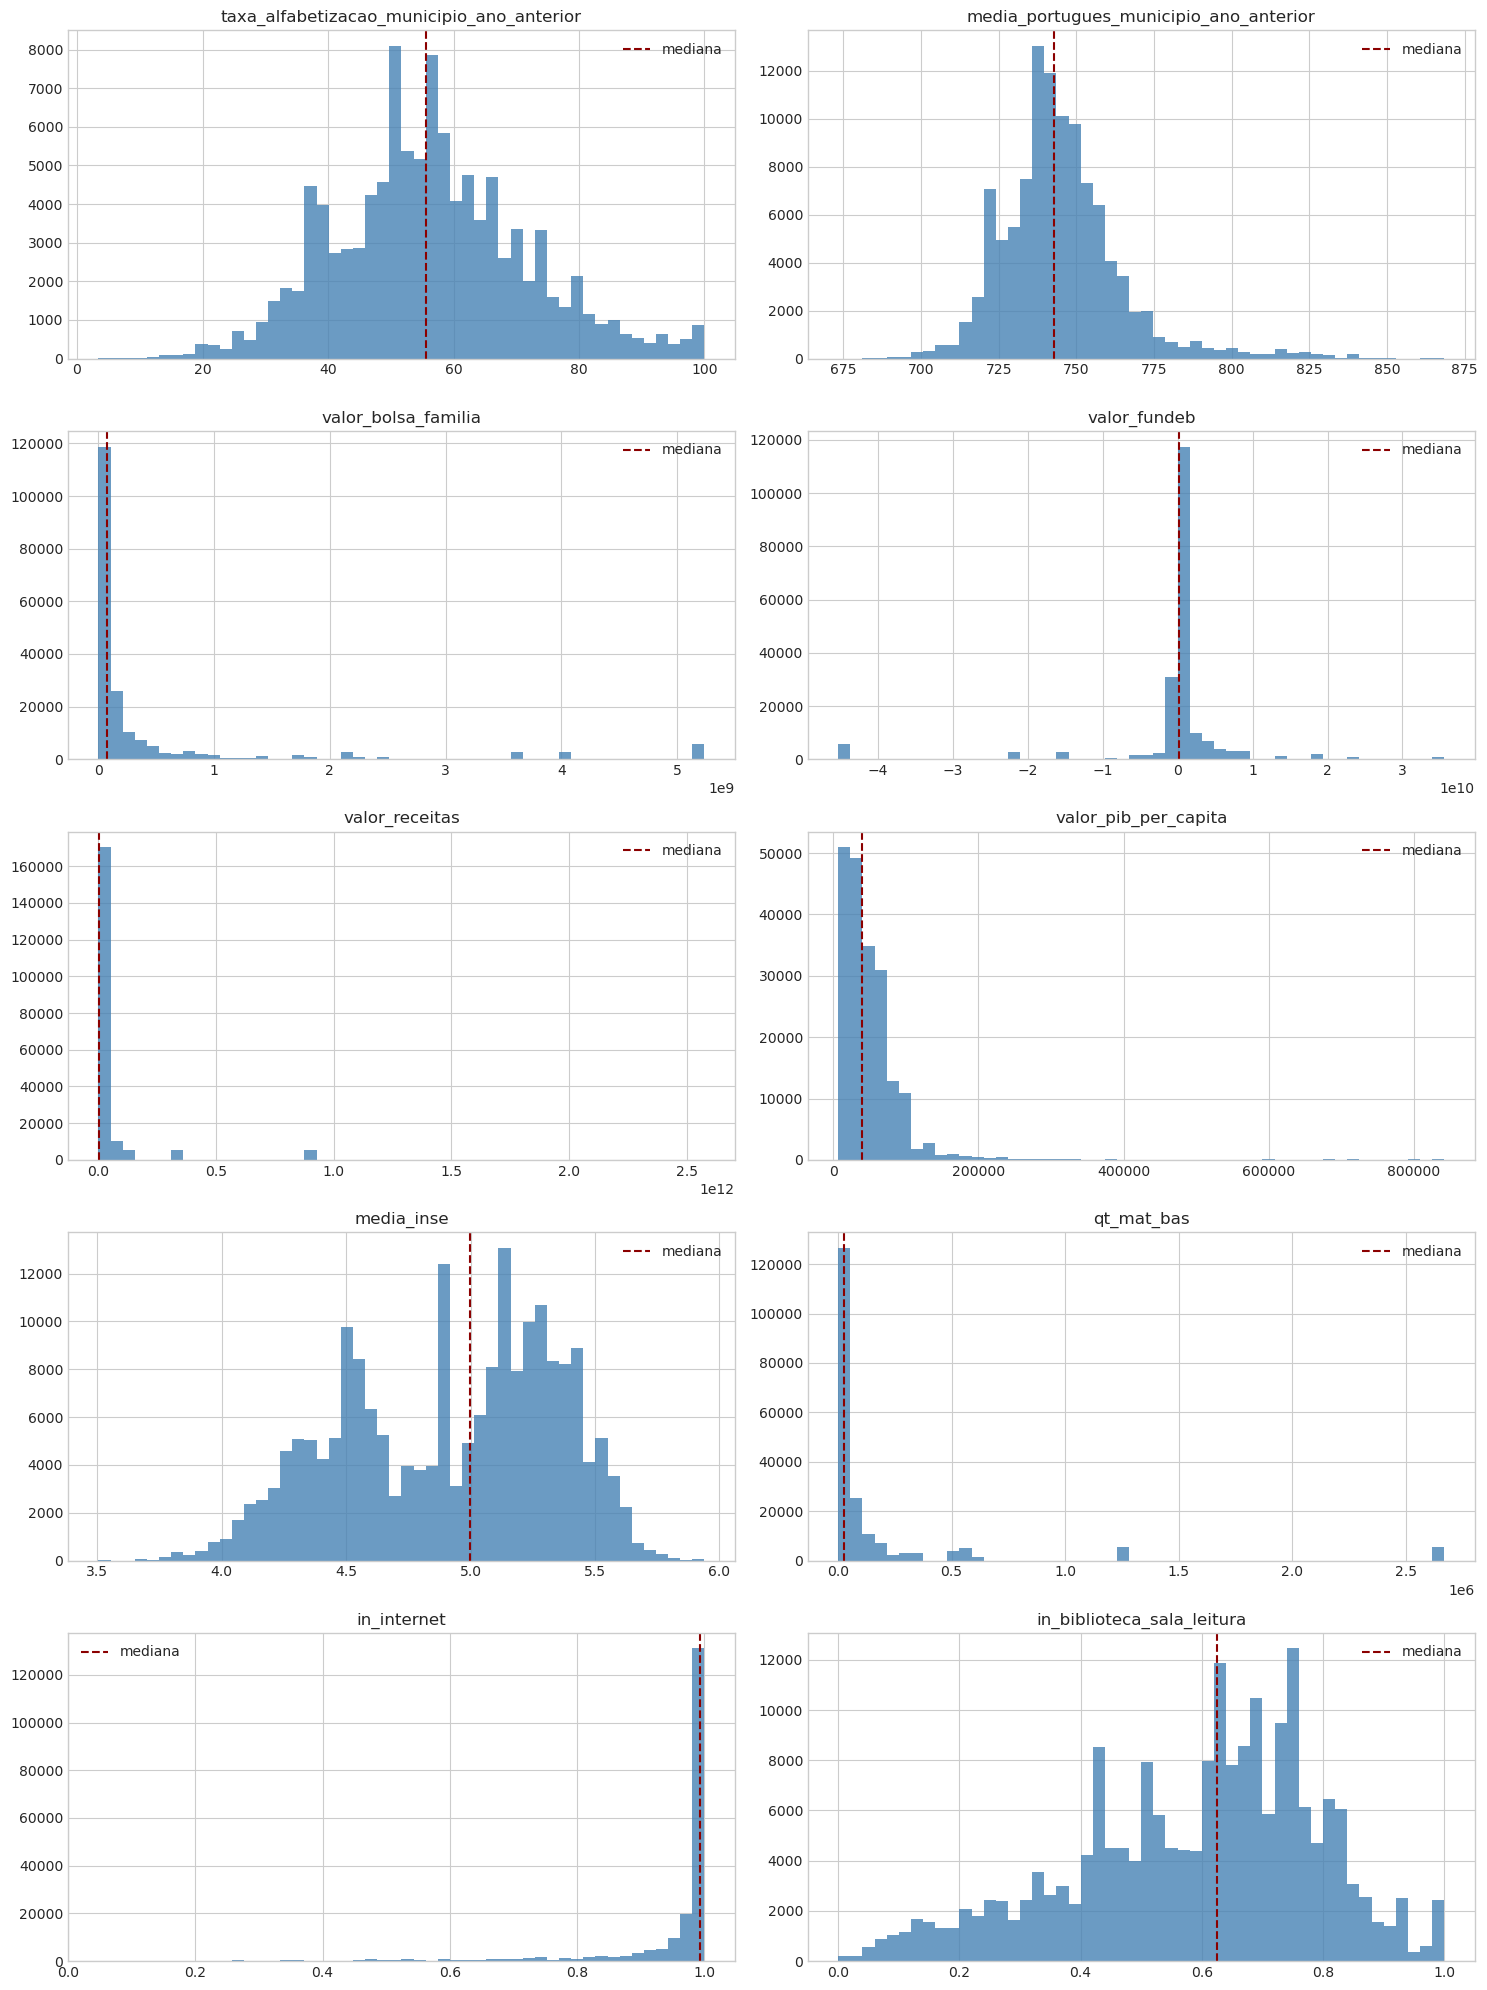

In [16]:
FEATURES_DISTRIBUICAO = [
    "taxa_alfabetizacao_municipio_ano_anterior",
    "media_portugues_municipio_ano_anterior", "valor_bolsa_familia",
    "valor_fundeb", "valor_receitas", "valor_pib_per_capita",
    "media_inse", "qt_mat_bas", "in_internet", "in_biblioteca_sala_leitura",
]
fracao_eda_distribuicao = min(1.0, 200_000 / total)
limite_hash_eda = max(1, round(fracao_eda_distribuicao * 10_000))
amostra_eda = (
    lf.filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL) % 10_000) < limite_hash_eda)
    .select(FEATURES_DISTRIBUICAO + [TARGET])
    .head(200_000)
    .collect(engine="streaming")
)

fig, axes = plt.subplots(5, 2, figsize=(15, 20))
for eixo, coluna in zip(axes.flatten(), FEATURES_DISTRIBUICAO):
    valores = amostra_eda[coluna].drop_nulls().to_numpy()
    eixo.hist(valores, bins=50, color="steelblue", alpha=0.8)
    eixo.axvline(float(np.median(valores)), color="darkred", linestyle="--", label="mediana")
    eixo.set_title(coluna)
    eixo.legend()
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "293_4_1_distribuicoes_e_assimetria_01.png"); plt.show()


### 4.2 Outliers e limites de domínio

O IQR sinaliza valores extremos, mas não determina remoção automática. Valores financeiros, matrículas e quantidades municipais podem ser legitimamente assimétricos. As proporções de infraestrutura, por outro lado, devem respeitar o intervalo de 0 a 1.


In [17]:
FEATURES_OUTLIERS = [
    "taxa_alfabetizacao_municipio_ano_anterior", "media_portugues_municipio_ano_anterior",
    "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
    "valor_pib", "valor_pib_per_capita", "media_inse",
    "qtd_alunos_inse", "qt_mat_bas", "qt_doc_bas", "qt_tur_bas",
]
quartis = lf.select([
    expr
    for c in FEATURES_OUTLIERS
    for expr in (pl.col(c).quantile(0.25).alias(f"{c}__q1"), pl.col(c).quantile(0.75).alias(f"{c}__q3"))
]).collect().row(0, named=True)

expressoes_outliers = []
limites_iqr = {}
for c in FEATURES_OUTLIERS:
    q1, q3 = quartis[f"{c}__q1"], quartis[f"{c}__q3"]
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    limites_iqr[c] = (inferior, superior)
    expressoes_outliers.append(((pl.col(c) < inferior) | (pl.col(c) > superior)).sum().alias(c))

contagem_outliers = lf.select(expressoes_outliers).collect().unpivot(
    variable_name="feature", value_name="quantidade_outliers"
).with_columns((100 * pl.col("quantidade_outliers") / total).round(2).alias("percentual_total")).sort(
    "percentual_total", descending=True
)
display(contagem_outliers)

PROPORCOES_INFRA = [c for c in NUMERIC_FEATURES if c.startswith("in_")]
violacoes_proporcao = lf.select([
    ((pl.col(c) < 0) | (pl.col(c) > 1)).sum().alias(c) for c in PROPORCOES_INFRA
]).collect().unpivot(variable_name="feature", value_name="fora_intervalo_0_1")
display(violacoes_proporcao)
assert violacoes_proporcao["fora_intervalo_0_1"].sum() == 0, "Há proporções de infraestrutura fora de 0 a 1."


feature,quantidade_outliers,percentual_total
str,u32,f64
"""valor_fundeb""",986371,25.5
"""valor_pib""",604083,15.62
"""qt_doc_bas""",583210,15.08
"""valor_bolsa_familia""",576396,14.9
"""qt_mat_bas""",570640,14.75
"""qt_tur_bas""",570640,14.75
"""valor_receitas""",551499,14.26
"""qtd_alunos_inse""",512940,13.26
"""valor_pib_per_capita""",152756,3.95


feature,fora_intervalo_0_1
str,u32
"""in_biblioteca_sala_leitura""",0
"""in_laboratorio_informatica""",0
"""in_quadra_esportes""",0
"""in_agua_rede_publica""",0
"""in_energia_rede_publica""",0
"""in_esgoto_rede_publica""",0
"""in_internet""",0
"""in_banda_larga""",0


### 4.3 Relações entre features e target

A matriz usa uma amostra reprodutível. Correlações altas entre features ajudam a identificar redundância; associação com o target é apenas evidência exploratória e não autoriza uma variável bloqueada por leakage.


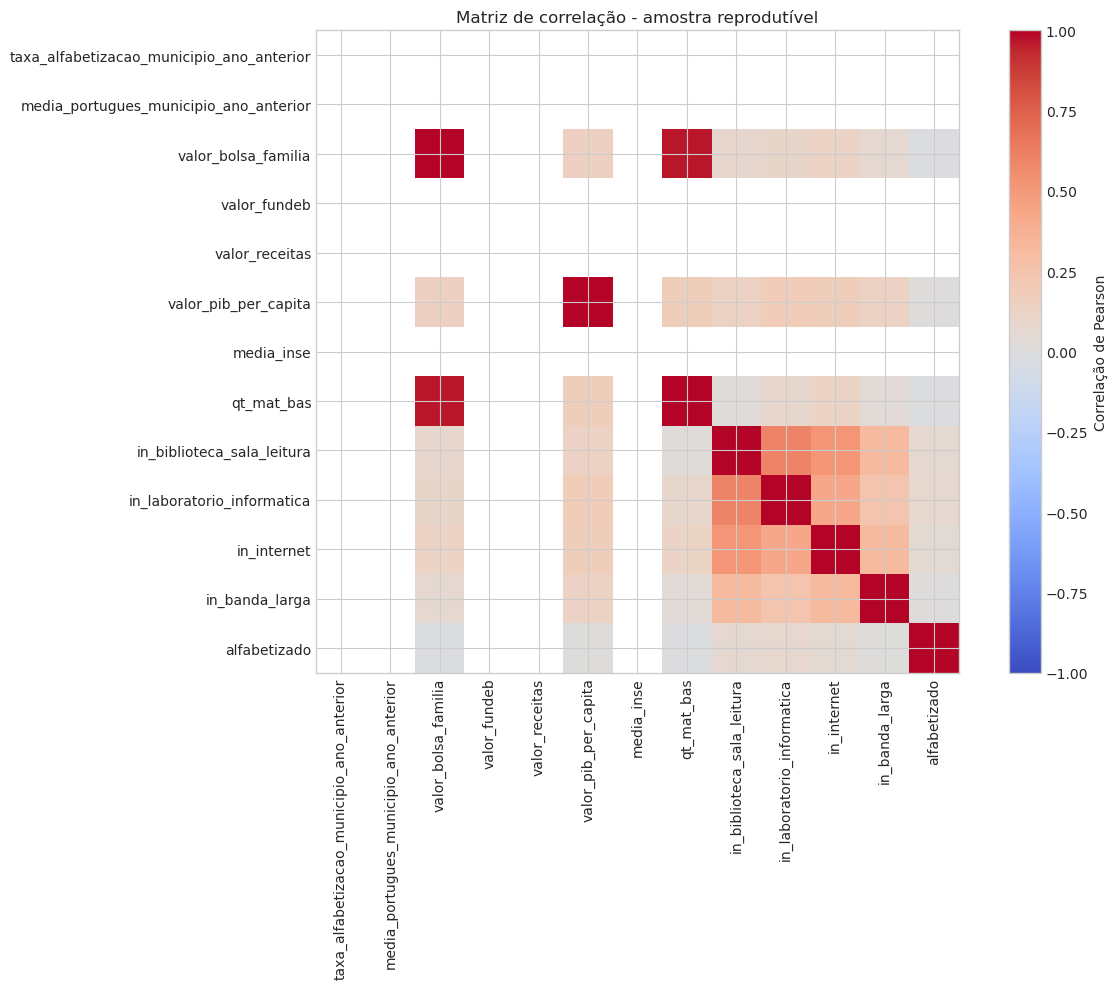

alfabetizado,taxa_alfabetizacao_municipio_ano_anterior__media,taxa_alfabetizacao_municipio_ano_anterior__mediana,media_portugues_municipio_ano_anterior__media,media_portugues_municipio_ano_anterior__mediana,valor_bolsa_familia__media,valor_bolsa_familia__mediana,valor_fundeb__media,valor_fundeb__mediana,valor_receitas__media,valor_receitas__mediana,valor_pib_per_capita__media,valor_pib_per_capita__mediana,media_inse__media,media_inse__mediana,qt_mat_bas__media,qt_mat_bas__mediana,in_internet__media,in_internet__mediana,in_biblioteca_sala_leitura__media,in_biblioteca_sala_leitura__mediana
i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,52.524938,52.2,739.974094,739.3033,4.8311e8,8.2065933e7,-7.1724e8,1.4971e8,5.4865e10,5.2082e9,49970.858879,39364.74,4.901466,4.920591,189254.263822,28897.0,0.939752,0.992624,0.578192,0.622449
1,59.767943,58.0,749.668175,746.3576,4.4037e8,5.8318002e7,-5.9367e8,1.4067e8,4.9676e10,4.0771e9,50163.076947,40350.57,4.937153,5.038918,174923.001202,21828.0,0.952242,0.994413,0.601334,0.631285


In [18]:
FEATURES_CORRELACAO = [
    "taxa_alfabetizacao_municipio_ano_anterior", "media_portugues_municipio_ano_anterior",
    "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
    "valor_pib_per_capita", "media_inse", "qt_mat_bas",
    "in_biblioteca_sala_leitura", "in_laboratorio_informatica",
    "in_internet", "in_banda_larga", TARGET,
]
limite_hash_corr = max(1, round(FRACOES_AMOSTRAGEM["eda_correlacao"] * 10_000))
amostra_corr = (
    lf.filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL) % 10_000) < limite_hash_corr)
    .select(FEATURES_CORRELACAO)
    .collect(engine="streaming")
)
matriz_corr = amostra_corr.corr()
plt.figure(figsize=(13, 10))
plt.imshow(matriz_corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlação de Pearson")
plt.xticks(range(len(matriz_corr.columns)), matriz_corr.columns, rotation=90)
plt.yticks(range(len(matriz_corr.columns)), matriz_corr.columns)
plt.title("Matriz de correlação - amostra reprodutível")
plt.tight_layout()
salvar_figura_eda(plt.gcf(), "297_4_3_relacoes_entre_features_e_target_01.png"); plt.show()

resumo_por_target = lf.group_by(TARGET).agg([
    expr for c in FEATURES_DISTRIBUICAO
    for expr in (pl.col(c).mean().alias(f"{c}__media"), pl.col(c).median().alias(f"{c}__mediana"))
]).sort(TARGET).collect()
display(resumo_por_target)


In [19]:
for coluna in CATEGORICAL_FEATURES:
    associacao = (
        lf.group_by([coluna, TARGET]).agg(pl.len().alias("quantidade"))
          .with_columns((100 * pl.col("quantidade") / pl.col("quantidade").sum().over(coluna)).round(2).alias("percentual_na_categoria"))
          .sort([coluna, TARGET]).collect()
    )
    print(f"\nAssociação de {coluna} com {TARGET}")
    display(associacao)



Associação de sigla_uf com alfabetizado


sigla_uf,alfabetizado,quantidade,percentual_na_categoria
str,i32,u32,f64
"""AC""",0,7344,58.03
"""AC""",1,5311,41.97
"""AL""",0,39133,56.57
"""AL""",1,30038,43.43
"""AM""",0,72843,59.87
"""AM""",1,48820,40.13
"""AP""",0,15018,60.24
"""AP""",1,9911,39.76
"""BA""",0,172390,68.06



Associação de rede com alfabetizado


rede,alfabetizado,quantidade,percentual_na_categoria
i32,i32,u32,f64
2,0,203976,46.85
2,1,231422,53.15
3,0,1679468,48.93
3,1,1753108,51.07
4,0,9,36.0
4,1,16,64.0


### 4.4 Recortes geográficos e de rede

Os resultados são descritivos. Diferenças entre grupos podem refletir composição, cobertura e participação; não demonstram efeito causal. Municípios são exibidos apenas quando possuem volume mínimo.


In [20]:
resumo_uf = lf.group_by("sigla_uf").agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
    pl.col("media_inse").mean().alias("media_inse"),
    pl.col("valor_pib_per_capita").mean().alias("pib_per_capita_medio"),
).sort("proporcao_alfabetizado", descending=True).collect()
display(resumo_uf)

resumo_rede = lf.group_by(["sigla_uf", "rede"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).sort(["sigla_uf", "registros"], descending=[False, True]).collect()
display(resumo_rede)

MIN_REGISTROS_MUNICIPIO = 500
resumo_municipio = lf.group_by(["id_municipio", "nome_municipio", "sigla_uf"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).filter(pl.col("registros") >= MIN_REGISTROS_MUNICIPIO).sort(
    "proporcao_alfabetizado", descending=True
).collect()
display(resumo_municipio.head(20))
display(resumo_municipio.tail(20))


sigla_uf,registros,proporcao_alfabetizado,media_inse,pib_per_capita_medio
str,u32,f64,f64,f64
"""CE""",190190,0.8211,4.396767,25163.876081
"""ES""",98020,0.625678,5.034294,52223.972404
"""GO""",160907,0.624702,5.127209,45820.226015
"""PR""",277446,0.622608,5.362918,55710.800054
"""MG""",413557,0.594436,5.103546,46402.706808
"""RO""",45507,0.565781,4.952906,45449.107718
"""PE""",168630,0.559788,4.494298,29116.4913
"""PI""",68207,0.532643,4.317957,23842.905066
"""MA""",144242,0.526393,4.368148,20903.997953


sigla_uf,rede,registros,proporcao_alfabetizado
str,i32,u32,f64
"""AC""",3,7098,0.395323
"""AC""",2,5557,0.450783
"""AL""",3,66031,0.438536
"""AL""",2,3140,0.344268
"""AM""",3,94032,0.370076
"""AM""",2,27631,0.507437
"""AP""",3,18214,0.415834
"""AP""",2,6715,0.348027
"""BA""",3,252748,0.319397


id_municipio,nome_municipio,sigla_uf,registros,proporcao_alfabetizado
i64,str,str,u32,f64
2304004,"""Coreaú""","""CE""",510,1.0
2310506,"""Pedra Branca""","""CE""",694,0.991354
2309409,"""Novo Oriente""","""CE""",759,0.985507
2312007,"""Santana do Acaraú""","""CE""",642,0.984424
2304236,"""Croatá""","""CE""",500,0.984
2305902,"""Ipueiras""","""CE""",883,0.983012
2201903,"""Bom Jesus""","""PI""",512,0.974609
2305001,"""Guaraciaba do Norte""","""CE""",1232,0.969968
2311959,"""Salitre""","""CE""",521,0.96737


id_municipio,nome_municipio,sigla_uf,registros,proporcao_alfabetizado
i64,str,str,u32,f64
2407104,"""Macaíba""","""RN""",1488,0.212366
2402600,"""Ceará-Mirim""","""RN""",1904,0.211134
2930105,"""Senhor do Bonfim""","""BA""",1025,0.206829
1502806,"""Curralinho""","""PA""",1439,0.205003
4218004,"""Tijucas""","""SC""",1472,0.203804
1505205,"""Oeiras do Pará""","""PA""",1076,0.201673
2910602,"""Esplanada""","""BA""",741,0.20108
2910503,"""Entre Rios""","""BA""",667,0.1994
2805406,"""Poço Redondo""","""SE""",763,0.199214


### 4.5 Relações temporais

A comparação é agregada por ano e não representa acompanhamento longitudinal garantido dos mesmos alunos. Mudanças também podem refletir cobertura diferente das fontes complementares.


In [21]:
resumo_temporal = lf.group_by("ano_referencia").agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
    *[pl.col(c).mean().alias(f"media__{c}") for c in [
        "taxa_alfabetizacao_municipio_ano_anterior", "media_portugues_municipio_ano_anterior",
        "valor_bolsa_familia", "valor_fundeb", "valor_receitas",
        "valor_pib_per_capita", "media_inse", "in_internet",
    ]],
).sort("ano_referencia").collect()
display(resumo_temporal)

resumo_uf_ano = lf.group_by(["ano_referencia", "sigla_uf"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).sort(["sigla_uf", "ano_referencia"]).collect()
display(resumo_uf_ano)

resumo_rede_ano = lf.group_by(["ano_referencia", "rede"]).agg(
    pl.len().alias("registros"),
    pl.col(TARGET).mean().alias("proporcao_alfabetizado"),
).sort(["rede", "ano_referencia"]).collect()
display(resumo_rede_ano)


ano_referencia,registros,proporcao_alfabetizado,media__taxa_alfabetizacao_municipio_ano_anterior,media__media_portugues_municipio_ano_anterior,media__valor_bolsa_familia,media__valor_fundeb,media__valor_receitas,media__valor_pib_per_capita,media__media_inse,media__in_internet
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
2023,1747439,0.502122,null,null,3.0974e8,4.0149e8,2.9606e10,43918.979755,4.868315,0.941589
2024,2120560,0.522088,56.315463,745.047354,5.8597e8,-1.5347e9,7.1076e10,55137.774789,4.96217,0.949927


ano_referencia,sigla_uf,registros,proporcao_alfabetizado
i64,str,u32,f64
2024,"""AC""",12655,0.419676
2023,"""AL""",35503,0.410782
2024,"""AL""",33668,0.459012
2023,"""AM""",63055,0.405709
2024,"""AM""",58608,0.396499
2023,"""AP""",12349,0.373229
2024,"""AP""",12580,0.421463
2023,"""BA""",137724,0.315747
2024,"""BA""",115576,0.323804


ano_referencia,rede,registros,proporcao_alfabetizado
i64,i32,u32,f64
2023,2,155140,0.51993
2024,2,280258,0.537933
2023,3,1592299,0.500387
2024,3,1840277,0.519673
2024,4,25,0.64


### 4.6 Fechamento do EDA

Decisões aplicadas na preparação:

- excluir variáveis da aplicação da avaliação por risco de leakage;
- manter somente `media_inse`, removendo os percentuais INSE correlacionados e composicionais;
- manter as proporções de infraestrutura e remover contagens redundantes de porte escolar;
- manter PIB per capita e remover PIB total;
- manter somente versões `signed_log1p` das variáveis financeiras;
- usar a fotografia municipal de INSE, Censo e PIB de 2023 também como contexto de 2024;
- excluir indicadores históricos municipais que não existem para 2023, evitando imputação de quase metade da base;
- não remover outliers municipais automaticamente; usar transformações robustas para valores financeiros;
- consolidar ausência em três flags de cobertura e imputar resíduos usando somente estatísticas do treino;
- manter chaves apenas para auditoria;
- deixar encoding e padronização dependentes do algoritmo dentro do pipeline de modelagem.


### 4.7 EDA e validação das metas oficiais

As metas oficiais são avaliadas como uma dimensão analítica separada. O target do modelo por aluno continua sendo `alfabetizado`; `meta_alfabetizacao` não entra nas features nem é usada no ajuste dos modelos. Depois da inferência, as probabilidades serão agregadas territorialmente e comparadas com esta referência.

Regras de granularidade:

- município: `id_municipio + rede=3 + ano_publicacao + ano_meta`;
- UF: `sigla_uf + rede=5 + ano_publicacao + ano_meta`;
- Brasil: `rede=5 + ano_publicacao + ano_meta`;
- rede 5 representa o agregado público das redes estadual (2) e municipal (3); não deve ser ligada diretamente a uma linha de aluno.


In [22]:
METAS_INPUT_ROOT = PROJECT_ROOT / "dados" / "fontes_originais" / "complementar" / "metas_alfabetizacao_oficiais"
METAS_OUTPUT_DIR = DADOS_PROCESSADOS_DIR / "preparado" / "metas_alfabetizacao_validadas"
METAS_MANIFEST_PATH = METAS_OUTPUT_DIR.parent / "manifesto_metas_alfabetizacao.json"

METAS_PATHS = {
    "municipio": METAS_INPUT_ROOT / "metas_vs_resultado_municipio",
    "uf": METAS_INPUT_ROOT / "metas_vs_resultado_uf",
    "brasil": METAS_INPUT_ROOT / "metas_vs_resultado_brasil",
}

def scan_meta(diretorio: Path) -> pl.LazyFrame:
    arquivos_meta = sorted(diretorio.glob("ano=*/*.parquet"))
    if not arquivos_meta:
        raise FileNotFoundError(f"Nenhum Parquet de metas localizado em {diretorio}")
    return pl.scan_parquet([str(p) for p in arquivos_meta], hive_partitioning=True)

metas_municipio = scan_meta(METAS_PATHS["municipio"])
metas_uf = scan_meta(METAS_PATHS["uf"])
metas_brasil = scan_meta(METAS_PATHS["brasil"])

for nome, frame in {
    "municipio": metas_municipio,
    "uf": metas_uf,
    "brasil": metas_brasil,
}.items():
    print(nome, frame.collect_schema().names())


municipio ['nivel_geografico', 'id_municipio', 'nome_municipio', 'sigla_uf', 'ano_observacao', 'serie', 'serie_descricao', 'rede', 'rede_descricao', 'taxa_alfabetizacao', 'qtd_alunos', 'origem_indicador', 'escopo_meta', 'ano_meta', 'meta_alfabetizacao', 'gap_pp', 'percentual_da_meta', 'atingiu_meta', 'meta_ja_vencida', 'processed_at', 'ano']
uf ['nivel_geografico', 'sigla_uf', 'ano_observacao', 'serie', 'serie_descricao', 'rede', 'rede_descricao', 'taxa_alfabetizacao', 'qtd_alunos', 'origem_indicador', 'escopo_meta', 'ano_meta', 'meta_alfabetizacao', 'gap_pp', 'percentual_da_meta', 'atingiu_meta', 'meta_ja_vencida', 'processed_at', 'ano']
brasil ['nivel_geografico', 'ano_observacao', 'serie', 'serie_descricao', 'rede', 'rede_descricao', 'taxa_alfabetizacao', 'qtd_alunos', 'origem_indicador', 'escopo_meta', 'ano_meta', 'meta_alfabetizacao', 'gap_pp', 'percentual_da_meta', 'atingiu_meta', 'meta_ja_vencida', 'processed_at', 'ano']


In [23]:
def resumo_qualidade_meta(nome: str, frame: pl.LazyFrame) -> pl.DataFrame:
    return frame.select(
        pl.lit(nome).alias("base"),
        pl.len().alias("registros"),
        pl.col("ano_observacao").min().alias("ano_observacao_min"),
        pl.col("ano_observacao").max().alias("ano_observacao_max"),
        pl.col("ano_meta").min().alias("ano_meta_min"),
        pl.col("ano_meta").max().alias("ano_meta_max"),
        pl.col("meta_alfabetizacao").null_count().alias("metas_nulas"),
        ((pl.col("meta_alfabetizacao") < 0) | (pl.col("meta_alfabetizacao") > 100)).sum().alias("metas_fora_0_100"),
    ).collect()

resumo_metas = pl.concat([
    resumo_qualidade_meta("municipio", metas_municipio),
    resumo_qualidade_meta("uf", metas_uf),
    resumo_qualidade_meta("brasil", metas_brasil),
])
display(resumo_metas)

assert resumo_metas["metas_nulas"].sum() == 0, "Existem metas nulas."
assert resumo_metas["metas_fora_0_100"].sum() == 0, "Existem metas fora do intervalo percentual."

redes_por_escopo = pl.concat([
    metas_municipio.select("escopo_meta", "rede", "rede_descricao"),
    metas_uf.select("escopo_meta", "rede", "rede_descricao"),
    metas_brasil.select("escopo_meta", "rede", "rede_descricao"),
]).unique().sort(["escopo_meta", "rede"]).collect()
display(redes_por_escopo)

assert set(
    redes_por_escopo.filter(pl.col("escopo_meta") == "municipio")["rede"].to_list()
) == {3}
assert set(
    redes_por_escopo.filter(pl.col("escopo_meta").is_in(["uf", "brasil"]))["rede"].to_list()
) == {5}


base,registros,ano_observacao_min,ano_observacao_max,ano_meta_min,ano_meta_max,metas_nulas,metas_fora_0_100
str,u32,i32,i32,i32,i32,u32,u32
"""municipio""",147650,2023,2024,2024,2030,0,0
"""uf""",685,2023,2024,2024,2030,0,0
"""brasil""",14,2023,2024,2024,2030,0,0


escopo_meta,rede,rede_descricao
str,i32,str
"""brasil""",5,"""Pública (Estadual e Municipal)"""
"""municipio""",3,"""Municipal"""
"""uf""",5,"""Pública (Estadual e Municipal)"""


In [24]:
metas_municipais_ids = (
    metas_municipio
    .filter((pl.col("escopo_meta") == "municipio") & (pl.col("rede") == 3))
    .select(pl.col("id_municipio").cast(pl.String))
    .unique()
    .with_columns(pl.lit(True).alias("tem_meta_municipal"))
)

municipios_tc3_rede_municipal = (
    lf.filter(pl.col("rede") == 3)
    .select(
        pl.col("id_municipio").cast(pl.String),
        pl.col("nome_municipio"),
        pl.col("sigla_uf"),
    )
    .unique()
)

cobertura_municipal = (
    municipios_tc3_rede_municipal
    .join(metas_municipais_ids, on="id_municipio", how="left")
    .with_columns(pl.col("tem_meta_municipal").fill_null(False))
)

resumo_cobertura_municipal = cobertura_municipal.select(
    pl.len().alias("municipios_tc3_rede_municipal"),
    pl.col("tem_meta_municipal").sum().alias("municipios_com_meta"),
    (~pl.col("tem_meta_municipal")).sum().alias("municipios_sem_meta"),
    pl.col("tem_meta_municipal").mean().alias("proporcao_coberta"),
).collect()
display(resumo_cobertura_municipal)

municipios_sem_meta = (
    cobertura_municipal.filter(~pl.col("tem_meta_municipal"))
    .select("id_municipio", "nome_municipio", "sigla_uf")
    .sort(["sigla_uf", "nome_municipio"])
    .collect()
)
display(municipios_sem_meta.head(30))

ufs_tc3 = set(lf.select(pl.col("sigla_uf").drop_nulls().unique()).collect()["sigla_uf"].to_list())
ufs_meta = set(
    metas_uf.filter(pl.col("escopo_meta") == "uf")
    .select(pl.col("sigla_uf").drop_nulls().unique())
    .collect()["sigla_uf"].to_list()
)
ufs_sem_meta_propria = sorted(ufs_tc3 - ufs_meta)
display(pl.DataFrame({
    "uf_sem_meta_propria": ufs_sem_meta_propria,
    "tratamento": [
        "Distrito Federal: usar somente a referência Brasil/rede pública; a fonte não publica meta no escopo UF."
        if uf == "DF" else "Revisar ausência não prevista"
        for uf in ufs_sem_meta_propria
    ],
}))

# O Distrito Federal não é dividido em municípios e, na base do TC3, aparece
# somente como rede estadual (2). A fonte oficial não trouxe linha de escopo UF
# para DF; há, porém, a trajetória Brasil/rede pública (5). A exceção é
# documentada, não imputada como se fosse uma meta própria do DF.
EXCECOES_UF_SEM_META_PROPRIA = {"DF"}
ausencias_uf_inesperadas = set(ufs_sem_meta_propria) - EXCECOES_UF_SEM_META_PROPRIA
assert not ausencias_uf_inesperadas, (
    f"Há UFs sem referência oficial e sem regra documentada: {sorted(ausencias_uf_inesperadas)}"
)
assert metas_brasil.filter(
    (pl.col("escopo_meta") == "brasil") & (pl.col("rede") == 5)
).select(pl.len()).collect().item() > 0, "A referência Brasil/rede pública está ausente."


municipios_tc3_rede_municipal,municipios_com_meta,municipios_sem_meta,proporcao_coberta
u32,u32,u32,f64
5498,5352,146,0.973445


id_municipio,nome_municipio,sigla_uf
str,str,str
"""1300300""","""Autazes""","""AM"""
"""1300631""","""Beruri""","""AM"""
"""1300904""","""Canutama""","""AM"""
"""1301100""","""Careiro""","""AM"""
"""1301407""","""Eirunepé""","""AM"""
"""1301605""","""Fonte Boa""","""AM"""
"""1302009""","""Itapiranga""","""AM"""
"""2904753""","""Buritirama""","""BA"""
"""2904852""","""Cabaceiras do Paraguaçu""","""BA"""


uf_sem_meta_propria,tratamento
str,str
"""DF""","""Distrito Federal: usar somente…"


escopo_meta,ano_publicacao,ano_meta,referencias,meta_min,meta_mediana,meta_max
str,i32,i32,u32,f64,f64,f64
"""brasil""",2023,2024,1,59.9,59.9,59.9
"""brasil""",2023,2025,1,63.77,63.77,63.77
"""brasil""",2023,2026,1,67.47,67.47,67.47
"""brasil""",2023,2027,1,70.97,70.97,70.97
"""brasil""",2023,2028,1,74.23,74.23,74.23
"""brasil""",2023,2029,1,77.24,77.24,77.24
"""brasil""",2023,2030,1,80.0,80.0,80.0
"""brasil""",2024,2024,1,59.9,59.9,59.9
"""brasil""",2024,2025,1,63.77,63.77,63.77


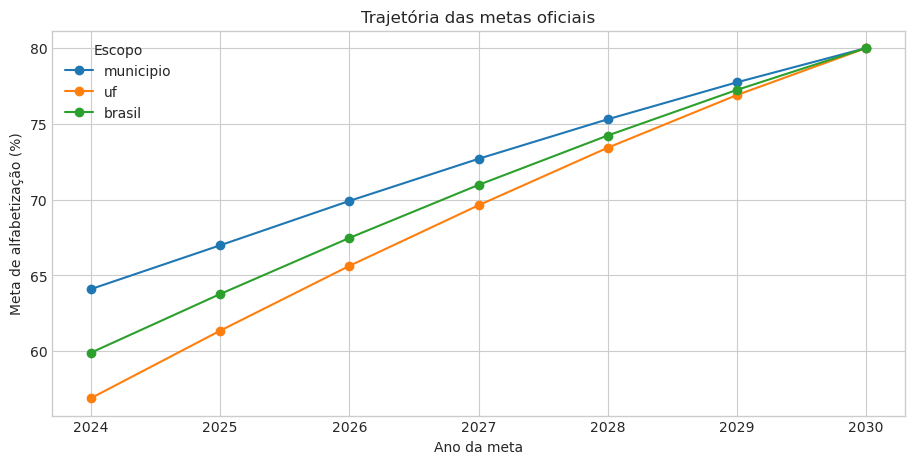

In [25]:
metas_municipio_ref = (
    metas_municipio.filter(pl.col("escopo_meta") == "municipio")
    .select(
        pl.lit("municipio").alias("escopo_meta"),
        pl.col("id_municipio").cast(pl.String),
        pl.col("sigla_uf").cast(pl.String),
        pl.col("rede").cast(pl.Int32),
        pl.col("rede_descricao"),
        pl.col("ano_observacao").cast(pl.Int32).alias("ano_publicacao"),
        pl.col("ano_meta").cast(pl.Int32),
        pl.col("meta_alfabetizacao").cast(pl.Float64),
        pl.lit("metas_vs_resultado_municipio").alias("produto_origem"),
    )
)

metas_uf_ref = (
    metas_uf.filter(pl.col("escopo_meta") == "uf")
    .select(
        pl.lit("uf").alias("escopo_meta"),
        pl.lit(None, dtype=pl.String).alias("id_municipio"),
        pl.col("sigla_uf").cast(pl.String),
        pl.col("rede").cast(pl.Int32),
        pl.col("rede_descricao"),
        pl.col("ano_observacao").cast(pl.Int32).alias("ano_publicacao"),
        pl.col("ano_meta").cast(pl.Int32),
        pl.col("meta_alfabetizacao").cast(pl.Float64),
        pl.lit("metas_vs_resultado_uf").alias("produto_origem"),
    )
)

metas_brasil_ref = (
    metas_brasil.filter(pl.col("escopo_meta") == "brasil")
    .select(
        pl.lit("brasil").alias("escopo_meta"),
        pl.lit(None, dtype=pl.String).alias("id_municipio"),
        pl.lit(None, dtype=pl.String).alias("sigla_uf"),
        pl.col("rede").cast(pl.Int32),
        pl.col("rede_descricao"),
        pl.col("ano_observacao").cast(pl.Int32).alias("ano_publicacao"),
        pl.col("ano_meta").cast(pl.Int32),
        pl.col("meta_alfabetizacao").cast(pl.Float64),
        pl.lit("metas_vs_resultado_brasil").alias("produto_origem"),
    )
)

metas_canonicas = pl.concat(
    [metas_municipio_ref, metas_uf_ref, metas_brasil_ref],
    how="diagonal_relaxed",
)

CHAVE_META = [
    "escopo_meta", "id_municipio", "sigla_uf", "rede",
    "ano_publicacao", "ano_meta",
]
duplicidades_meta = (
    metas_canonicas.group_by(CHAVE_META).len()
    .filter(pl.col("len") > 1)
    .collect()
)
assert duplicidades_meta.is_empty(), f"Chaves duplicadas na referência de metas: {duplicidades_meta}"
assert metas_canonicas.filter(pl.col("ano_meta") < pl.col("ano_publicacao")).select(pl.len()).collect().item() == 0

evolucao_metas = (
    metas_canonicas.group_by("escopo_meta", "ano_publicacao", "ano_meta")
    .agg(
        pl.len().alias("referencias"),
        pl.col("meta_alfabetizacao").min().alias("meta_min"),
        pl.col("meta_alfabetizacao").median().alias("meta_mediana"),
        pl.col("meta_alfabetizacao").max().alias("meta_max"),
    )
    .sort(["escopo_meta", "ano_publicacao", "ano_meta"])
    .collect()
)
display(evolucao_metas)

fig, ax = plt.subplots(figsize=(11, 5))
for escopo in ["municipio", "uf", "brasil"]:
    serie = (
        evolucao_metas.filter(pl.col("escopo_meta") == escopo)
        .group_by("ano_meta")
        .agg(pl.col("meta_mediana").mean().alias("meta_mediana"))
        .sort("ano_meta")
    )
    ax.plot(serie["ano_meta"], serie["meta_mediana"], marker="o", label=escopo)
ax.set(title="Trajetória das metas oficiais", xlabel="Ano da meta", ylabel="Meta de alfabetização (%)")
ax.legend(title="Escopo")
salvar_figura_eda(plt.gcf(), "308_4_7_eda_e_validacao_das_metas_oficiais_01.png"); plt.show()


In [26]:
METAS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
arquivos_metas_existentes = list(METAS_OUTPUT_DIR.rglob("*.parquet"))

if deve_recalcular(METAS_OUTPUT_DIR) or not arquivos_metas_existentes:
    quantidade_publicada = publicar_parquet_particionado(
        metas_canonicas, METAS_OUTPUT_DIR, particionar_por="escopo_meta"
    )
    print(f"Referência canônica de metas gravada: {quantidade_publicada} arquivo(s).")
else:
    metas_publicadas = pl.scan_parquet(
        str(METAS_OUTPUT_DIR / "escopo_meta=*" / "*.parquet"),
        hive_partitioning=True,
    )
    assert metas_publicadas.collect_schema().names() == metas_canonicas.collect_schema().names()
    print(f"Referência existente validada e reutilizada: {len(arquivos_metas_existentes)} arquivos.")

resumo_canonico = metas_canonicas.select(
    pl.len().alias("registros"),
    pl.col("escopo_meta").n_unique().alias("escopos"),
    pl.col("ano_meta").min().alias("ano_meta_min"),
    pl.col("ano_meta").max().alias("ano_meta_max"),
).collect()

manifesto_metas = {
    "produto": "metas_alfabetizacao_validadas_tc3",
    "versao_contrato": 1,
    "uso": "referencia_pos_modelagem; nao utilizar como feature do modelo por aluno",
    "fontes": [str(path.relative_to(PROJECT_ROOT)).replace("\\", "/") for path in METAS_PATHS.values()],
    "caminho_relativo": str(METAS_OUTPUT_DIR.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "graos": {
        "municipio": "id_municipio + rede=3 + ano_publicacao + ano_meta",
        "uf": "sigla_uf + rede=5 + ano_publicacao + ano_meta",
        "brasil": "rede=5 + ano_publicacao + ano_meta",
    },
    "registros": resumo_canonico["registros"].item(),
    "ano_meta_min": resumo_canonico["ano_meta_min"].item(),
    "ano_meta_max": resumo_canonico["ano_meta_max"].item(),
    "municipios_tc3_rede_municipal": resumo_cobertura_municipal["municipios_tc3_rede_municipal"].item(),
    "municipios_com_meta": resumo_cobertura_municipal["municipios_com_meta"].item(),
    "municipios_sem_meta": resumo_cobertura_municipal["municipios_sem_meta"].item(),
}
METAS_MANIFEST_PATH.write_text(
    json.dumps(manifesto_metas, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print(f"Metas validadas: {METAS_OUTPUT_DIR}")
print(f"Manifesto: {METAS_MANIFEST_PATH}")


Referência canônica de metas gravada: 3 arquivo(s).
Metas validadas: /workspace/dados/dados_processados/preparado/metas_alfabetizacao_validadas
Manifesto: /workspace/dados/dados_processados/preparado/manifesto_metas_alfabetizacao.json


#### Decisão metodológica sobre as metas

O EDA das metas não altera o contrato da base de modelagem. A referência canônica será consumida somente após a inferência:

1. gerar probabilidades individuais de alfabetização;
2. agregar as probabilidades no grão compatível com a meta;
3. para município, comparar somente a rede municipal (`rede=3`);
4. para UF e Brasil, combinar as redes estadual e municipal antes de comparar com a rede pública agregada (`rede=5`);
5. escolher a revisão da meta que já estava publicada no ano da previsão;
6. registrar separadamente territórios sem correspondência, sem imputar metas oficiais.

Os campos `gap_pp`, `atingiu_meta` e `meta_ja_vencida` das tabelas de origem descrevem resultados históricos. Eles não são transportados para a referência canônica porque deverão ser recalculados sobre as previsões do modelo.


## 5. Preparação sem vazamento entre splits

Antes da preparação, a rede privada (`rede = 4`) é excluída do produto de modelagem: são apenas 25 registros, todos de 2024 e concentrados em uma única escola anonimizada de Gurupi/TO. Essa cobertura não sustenta aprendizado ou avaliação representativa da rede privada. A camada consolidada permanece intacta e a decisão restringe explicitamente o escopo do modelo às redes estadual e municipal.

Valores ausentes recebem uma flag explícita. A mediana usada na imputação é calculada somente no treino. Variáveis categóricas ausentes recebem `DESCONHECIDO`. Valores financeiros são preservados e recebem também uma transformação logarítmica com sinal, adequada inclusive para valores negativos de Fundeb.

Encoding e padronização dependentes do algoritmo devem ser ajustados posteriormente dentro do pipeline de treinamento, nunca sobre a base completa.


In [27]:
valores_split = lf.select(pl.col("dataset_split").drop_nulls().unique().sort()).collect()["dataset_split"].to_list()
print("Valores de dataset_split:", valores_split)
train_candidates = [v for v in valores_split if str(v).strip().lower() in {"train", "treino", "training"}]
if len(train_candidates) != 1:
    raise ValueError("Não foi possível identificar unicamente o conjunto de treino em dataset_split.")
TRAIN_LABEL = train_candidates[0]

# A rede privada tem somente 25 observações de uma escola em Gurupi/TO. Ela é
# preservada na camada consolidada, mas retirada do escopo de modelagem.
base_escopo = lf.filter(~pl.col("rede").is_in(list(EXCLUDED_NETWORKS)))
total_modelagem = base_escopo.select(pl.len()).collect().item()
registros_excluidos_rede = total - total_modelagem
assert registros_excluidos_rede == 25, f"Quantidade inesperada excluída por rede: {registros_excluidos_rede}"
print(f"Registros fora do escopo de modelagem: {registros_excluidos_rede}")
print(f"Registros no escopo estadual/municipal: {total_modelagem:,}")

# INSE, Censo e PIB de 2023 são uma fotografia contextual. Para 2024, usa-se a
# referência municipal de 2023, sem recorrer a informação futura.
CHAVES_CONTEXTO = ["id_municipio", "sigla_uf"]
referencia_2023 = (
    base_escopo.filter(pl.col("ano_referencia") == 2023)
      .group_by(CHAVES_CONTEXTO)
      .agg([pl.col(c).drop_nulls().first().alias(f"{c}__ref_2023") for c in STATIC_2023_FEATURES])
)
base_enriquecida = (
    base_escopo.join(referencia_2023, on=CHAVES_CONTEXTO, how="left", validate="m:1")
      .with_columns([pl.coalesce([pl.col(c), pl.col(f"{c}__ref_2023")]).alias(c) for c in STATIC_2023_FEATURES])
      .drop([f"{c}__ref_2023" for c in STATIC_2023_FEATURES])
)

medianas_treino = (
    base_enriquecida.filter(pl.col("dataset_split") == TRAIN_LABEL)
      .select([pl.col(c).cast(pl.Float64, strict=False).median().alias(c) for c in FINAL_SOURCE_FEATURES if c != "ano_referencia"])
      .collect()
      .row(0, named=True)
)
medianas_treino


Valores de dataset_split: ['teste', 'treino', 'validacao']
Registros fora do escopo de modelagem: 25
Registros no escopo estadual/municipal: 3,867,974


{'valor_bolsa_familia': 69476037.0,
 'valor_fundeb': 145010051.03,
 'valor_receitas': 4588630098.32,
 'valor_pib_per_capita': 40059.08,
 'media_inse': 4.999194373401535,
 'in_biblioteca_sala_leitura': 0.625,
 'in_laboratorio_informatica': 0.3503861003861004,
 'in_quadra_esportes': 0.4603174603174603,
 'in_agua_rede_publica': 0.9285714285714286,
 'in_energia_rede_publica': 1.0,
 'in_esgoto_rede_publica': 0.71875,
 'in_internet': 0.9931053502482073,
 'in_banda_larga': 0.9302325581395349}

In [28]:
MONETARY_COLUMNS = CURRENT_FINANCIAL_FEATURES + ["valor_pib_per_capita"]
base_rastreavel = base_enriquecida.with_columns(
    pl.concat_str(
        [
            pl.col("ano_referencia").cast(pl.String),
            pl.col("id_municipio").cast(pl.String),
            pl.col("id_escola").cast(pl.String),
        ],
        separator="|",
    ).alias("chave_escola_ano")
)
prepared = (
    base_rastreavel.select(KEY_COLUMNS + CONTROL_COLUMNS + CATEGORICAL_FEATURES + FINAL_SOURCE_FEATURES + [TARGET])
      .with_columns(
          pl.any_horizontal([pl.col(c).is_null() for c in CURRENT_FINANCIAL_FEATURES]).cast(pl.Int8).alias("cobertura_financeira_ausente"),
          pl.col("media_inse").is_null().cast(pl.Int8).alias("cobertura_inse_ausente"),
      )
      .with_columns([pl.col(c).cast(pl.Float64, strict=False).fill_null(medianas_treino[c]).alias(c) for c in FINAL_SOURCE_FEATURES if c != "ano_referencia"])
      .with_columns([pl.col(c).cast(pl.String).fill_null("DESCONHECIDO").alias(c) for c in CATEGORICAL_FEATURES])
      .with_columns([
          (pl.col(c).sign() * (pl.col(c).abs() + 1).log()).alias(f"{c}__signed_log1p")
          for c in MONETARY_COLUMNS
      ])
      .select(KEY_COLUMNS + CONTROL_COLUMNS + [TARGET] + FINAL_MODEL_FEATURES)
)

prepared_schema = prepared.collect_schema()
print(f"Colunas da base preparada: {len(prepared_schema)}")
print(prepared_schema.names())


Colunas da base preparada: 24
['id_aluno', 'id_municipio', 'id_escola', 'chave_escola_ano', 'dataset_split', 'alfabetizado', 'sigla_uf', 'rede', 'ano_referencia', 'valor_bolsa_familia__signed_log1p', 'valor_fundeb__signed_log1p', 'valor_receitas__signed_log1p', 'valor_pib_per_capita__signed_log1p', 'media_inse', 'in_biblioteca_sala_leitura', 'in_laboratorio_informatica', 'in_quadra_esportes', 'in_agua_rede_publica', 'in_energia_rede_publica', 'in_esgoto_rede_publica', 'in_internet', 'in_banda_larga', 'cobertura_financeira_ausente', 'cobertura_inse_ausente']


## 6. Validações da base preparada

O fluxo valida explicitamente as 25 exclusões de escopo da rede privada e falha se perder qualquer outra linha, mantiver uma coluna de leakage ou produzir nulos nas features finais.


In [29]:
MODEL_FEATURE_COLUMNS = [
    c for c in prepared_schema.names()
    if c not in KEY_COLUMNS + CONTROL_COLUMNS + [TARGET]
]
assert MODEL_FEATURE_COLUMNS == FINAL_MODEL_FEATURES, (
    "O esquema preparado diverge do contrato final. "
    f"Esperado: {FINAL_MODEL_FEATURES}; obtido: {MODEL_FEATURE_COLUMNS}"
)
leakage_presente = sorted(set(LEAKAGE_COLUMNS) & set(prepared_schema.names()))
assert not leakage_presente, f"Colunas de leakage na base preparada: {leakage_presente}"

validacao = prepared.select(
    pl.len().alias("registros"),
    pl.col(TARGET).null_count().alias("target_nulo"),
    pl.sum_horizontal([pl.col(c).null_count() for c in MODEL_FEATURE_COLUMNS]).alias("nulos_features"),
).collect()
display(validacao)
assert validacao["registros"].item() == total_modelagem, "A preparação alterou a quantidade de linhas além da exclusão documentada."
assert prepared.filter(pl.col("rede") == "4").select(pl.len()).collect().item() == 0, "A rede privada permaneceu na base preparada."
assert validacao["target_nulo"].item() == 0, "O target contém nulos."
assert validacao["nulos_features"].item() == 0, "Ainda existem nulos nas features preparadas."
assert len(MODEL_FEATURE_COLUMNS) == len(FINAL_MODEL_FEATURES), f"Quantidade inesperada de features: {len(MODEL_FEATURE_COLUMNS)}"
assert set(["id_escola", "chave_escola_ano"]).issubset(KEY_COLUMNS)
assert not set(["id_escola", "chave_escola_ano"]) & set(MODEL_FEATURE_COLUMNS)

cardinalidade_final = prepared.select([pl.col(c).n_unique().alias(c) for c in MODEL_FEATURE_COLUMNS]).collect()
constantes = [c for c in MODEL_FEATURE_COLUMNS if cardinalidade_final[c].item() <= 1]
assert not constantes, f"Features constantes encontradas: {constantes}"
print(f"Contrato final validado: {len(MODEL_FEATURE_COLUMNS)} features, nenhuma constante, nenhum leakage e chaves escolares fora do modelo.")


registros,target_nulo,nulos_features
u32,u32,u32
3867974,0,0


Contrato final validado: 18 features, nenhuma constante, nenhum leakage e chaves escolares fora do modelo.


### 6.1 Auditoria da chave escolar anual

`chave_escola_ano` é uma chave técnica formada por ano, município e `id_escola`.
Ela serve para agrupamento e validação dentro de uma edição, mas não identifica a
escola real e não estabelece continuidade entre 2023 e 2024.


In [30]:
assert prepared.select(pl.col("id_escola").null_count()).collect().item() == 0
assert prepared.select(pl.col("chave_escola_ano").null_count()).collect().item() == 0

auditoria_chave_escola = prepared.select(
    pl.len().alias("registros"),
    pl.col("id_escola").n_unique().alias("ids_escola_distintos"),
    pl.col("chave_escola_ano").n_unique().alias("escolas_ano_distintas"),
).collect()
display(auditoria_chave_escola)

escolas_por_split = {
    split: set(
        prepared.filter(pl.col("dataset_split") == split)
        .select("chave_escola_ano").unique().collect()["chave_escola_ano"].to_list()
    )
    for split in ["treino", "validacao", "teste"]
}
sobreposicao_escolas = pl.DataFrame([
    {"pares": "treino x validacao", "escolas_ano_em_comum": len(escolas_por_split["treino"] & escolas_por_split["validacao"])},
    {"pares": "treino x teste", "escolas_ano_em_comum": len(escolas_por_split["treino"] & escolas_por_split["teste"])},
    {"pares": "validacao x teste", "escolas_ano_em_comum": len(escolas_por_split["validacao"] & escolas_por_split["teste"])},
])
display(sobreposicao_escolas)
print("A sobreposição é apenas diagnosticada: o split oficial atual é por aluno.")
print(f"Uma validação futura por escola/ano deverá construir splits agrupados sem alterar as {len(MODEL_FEATURE_COLUMNS)} features.")


registros,ids_escola_distintos,escolas_ano_distintas
u32,u32,u32
3867974,42811,79272


pares,escolas_ano_em_comum
str,i64
"""treino x validacao""",77177
"""treino x teste""",77120
"""validacao x teste""",75177


A sobreposição é apenas diagnosticada: o split oficial atual é por aluno.
Uma validação futura por escola/ano deverá construir splits agrupados sem alterar as 18 features.


## 7. Persistência dos produtos

A execução grava uma nova camada em `dados/dados_processados/preparado`, particionada por UF, além do contrato de decisões e do catálogo do produto final. A pasta do TC3-82 permanece intacta. A publicação contém somente as redes estadual e municipal.


In [31]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DECISION_PATH.parent.mkdir(parents=True, exist_ok=True)

# Se a saída já existe, ela é validada e reutilizada. A regeneração deve ser uma decisão explícita.
arquivos_saida_existentes = list(OUTPUT_DIR.rglob("*.parquet"))
if deve_recalcular(OUTPUT_DIR) or not arquivos_saida_existentes:
    quantidade_publicada = publicar_parquet_particionado(
        prepared, OUTPUT_DIR, particionar_por="sigla_uf"
    )
    print(f"Nova base preparada gravada: {quantidade_publicada} arquivo(s).")
else:
    print(f"Saída existente reutilizada: {len(arquivos_saida_existentes)} arquivos.")
decisoes.write_csv(DECISION_PATH)

catalogo_final = pl.DataFrame([
    {
        "coluna": c,
        "tipo": str(prepared_schema[c]),
        "papel": ("target" if c == TARGET else "chave" if c in KEY_COLUMNS else "controle" if c in CONTROL_COLUMNS else "feature_derivada" if c.endswith(("__ausente", "__signed_log1p")) else "feature"),
    }
    for c in prepared_schema.names()
])
catalogo_final.write_csv(DATA_DICTIONARY_PATH)
print(f"Base preparada: {OUTPUT_DIR}")
print(f"Decisões: {DECISION_PATH}")
print(f"Catálogo: {DATA_DICTIONARY_PATH}")


Nova base preparada gravada: 26 arquivo(s).
Base preparada: /workspace/dados/dados_processados/preparado/base_modelagem_final_com_chave_escola_por_uf
Decisões: /workspace/resultados/tabelas/dicionario_dados/decisoes_features_modelagem_com_chave_escola.csv
Catálogo: /workspace/resultados/tabelas/dicionario_dados/base_modelagem_catalogo_com_chave_escola.csv


## 8. Disponibilização para os próximos notebooks

A base preparada é publicada com um manifesto legível por máquina. Novos notebooks devem localizar o projeto, ler o manifesto e usar o padrão Parquet informado, evitando caminhos locais fixos e evitando retornar à base consolidada de 49 colunas sem justificativa.


In [32]:
OUTPUT_GLOB = str(OUTPUT_DIR / "sigla_uf=*" / "*.parquet")
base_publicada = pl.scan_parquet(OUTPUT_GLOB, hive_partitioning=True)
schema_publicado = base_publicada.collect_schema()
validacao_publicacao = base_publicada.select(
    pl.len().alias("registros"),
    pl.col("sigla_uf").n_unique().alias("ufs"),
    pl.col(TARGET).null_count().alias("target_nulo"),
).collect()
assert validacao_publicacao["registros"].item() == total_modelagem
assert base_publicada.filter(pl.col("rede") == "4").select(pl.len()).collect().item() == 0
assert validacao_publicacao["ufs"].item() == 26
assert schema_publicado.names() == prepared_schema.names()
display(validacao_publicacao)

manifesto = {
    "produto": "base_modelagem_final_tc3_com_chave_escola",
    "versao_contrato": 4,
    "escopo_redes": ["2 - Estadual", "3 - Municipal"],
    "exclusoes_escopo": {"rede_4_privada": registros_excluidos_rede},
    "formato": "parquet_particionado",
    "caminho_relativo": str(OUTPUT_DIR.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "padrao_leitura": str((OUTPUT_DIR / "sigla_uf=*" / "*.parquet").relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "particionamento": ["sigla_uf"],
    "registros": validacao_publicacao["registros"].item(),
    "quantidade_colunas": len(schema_publicado),
    "target": TARGET,
    "controle_split": "dataset_split",
    "chaves_rastreabilidade": KEY_COLUMNS,
    "semantica_chave_escola": "agrupamento anonimo anual; nao identifica escola real nem garante continuidade entre anos",
    "features_modelagem": [c for c in schema_publicado.names() if c not in KEY_COLUMNS + CONTROL_COLUMNS + [TARGET]],
    "catalogo_relativo": str(DATA_DICTIONARY_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
    "decisoes_relativo": str(DECISION_PATH.relative_to(PROJECT_ROOT)).replace("\\", "/"),
}
MANIFEST_PATH = OUTPUT_DIR.parent / "manifesto_base_modelagem_com_chave_escola.json"
MANIFEST_PATH.write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Manifesto publicado em: {MANIFEST_PATH}")


registros,ufs,target_nulo
u32,u32,u32
3867974,26,0


Manifesto publicado em: /workspace/dados/dados_processados/preparado/manifesto_base_modelagem_com_chave_escola.json


### Célula padrão para novos notebooks

Copie a célula seguinte para qualquer etapa de modelagem. Ela lê o manifesto, resolve o caminho a partir da raiz do repositório e devolve um `LazyFrame`.


In [33]:
from pathlib import Path
import json
import polars as pl

def carregar_base_modelagem() -> tuple[pl.LazyFrame, dict]:
    manifesto_path = DADOS_PROCESSADOS_DIR / "preparado" / "manifesto_base_modelagem_com_chave_escola.json"
    if not manifesto_path.exists():
        raise FileNotFoundError("Manifesto da base preparada não localizado. Execute as etapas anteriores.")
    contrato = json.loads(manifesto_path.read_text(encoding="utf-8"))
    # O manifesto sempre registra o caminho relativo à raiz do projeto,
    # inclusive quando os artefatos ficam na área temporária da sessão.
    padrao = PROJECT_ROOT / Path(contrato["padrao_leitura"])
    return pl.scan_parquet(str(padrao), hive_partitioning=True), contrato

dados_modelagem, contrato_modelagem = carregar_base_modelagem()
print(contrato_modelagem["produto"], contrato_modelagem["registros"], "registros")
print("Features disponíveis:", len(contrato_modelagem["features_modelagem"]))


base_modelagem_final_tc3_com_chave_escola 3867974 registros
Features disponíveis: 18


## 9. Critérios de conclusão

O fluxo é considerado concluído quando: todas as partições de entrada possuem o mesmo esquema; não existem duplicatas por aluno/ano; todas as 49 colunas recebem uma decisão; nenhuma coluna de leakage entra na base preparada; imputações são aprendidas apenas no treino; somente os 25 registros privados documentados são retirados; e os produtos finais são gravados separadamente da base consolidada.


# Continuação — Fase 4 e baseline da Fase 5

Esta seção continua o fluxo validado até a Fase 3 sem alterar sua base consolidada. Ela cobre:

- **TC3-49:** estratégia de pré-processamento;
- **TC3-50:** seleção e engenharia de features;
- **TC3-51:** pipeline reprodutível de preparação;
- **TC3-52:** baseline ingênuo para comparação dos próximos modelos.

O treino dos modelos supervisionados posteriores deve sempre ajustar transformações somente no split de treino.


## 10. TC3-49 — Estratégia de pré-processamento

| Grupo | Estratégia | Justificativa |
|---|---|---|
| `sigla_uf`, `rede` | One-hot encoding com categoria desconhecida ignorada | Evita impor ordem artificial e aceita categorias novas na inferência |
| Numéricas contínuas | Imputação defensiva pela mediana + padronização | A base já não possui nulos, mas o pipeline continua robusto a dados futuros |
| Flags de cobertura | Mantidas como 0/1 | Preservam informação sobre ausência original antes da imputação |
| Target | Sem transformação | Classificação binária |
| Identificadores | Fora de `X` | Servem apenas para rastreabilidade |

O `ColumnTransformer` será ajustado dentro de cada pipeline de modelo. Nenhum encoder, imputador ou scaler é ajustado previamente sobre validação ou teste.


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
    average_precision_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np

TARGET_MODELAGEM = contrato_modelagem["target"]
SPLIT_COLUMN = contrato_modelagem["controle_split"]
FEATURE_COLUMNS = contrato_modelagem["features_modelagem"]
CATEGORICAL_COLUMNS = ["sigla_uf", "rede"]
NUMERIC_COLUMNS = [c for c in FEATURE_COLUMNS if c not in CATEGORICAL_COLUMNS]
TRACE_COLUMNS = contrato_modelagem["chaves_rastreabilidade"]

schema_modelagem = dados_modelagem.collect_schema()
assert FEATURE_COLUMNS == contrato_modelagem["features_modelagem"]
assert set(CATEGORICAL_COLUMNS).issubset(FEATURE_COLUMNS)
assert not set(TRACE_COLUMNS) & set(FEATURE_COLUMNS)
assert TARGET_MODELAGEM not in FEATURE_COLUMNS
assert set(FEATURE_COLUMNS).issubset(schema_modelagem.names())
print(f"Contrato carregado: {len(FEATURE_COLUMNS)} features ({len(CATEGORICAL_COLUMNS)} categóricas e {len(NUMERIC_COLUMNS)} numéricas).")


Contrato carregado: 18 features (2 categóricas e 16 numéricas).


## 11. TC3-50 — Seleção e engenharia de features

A seleção foi concluída no EDA e é consumida diretamente do manifesto. As transformações já materializadas são:

- log com sinal para valores financeiros e PIB per capita;
- proporções municipais de infraestrutura no intervalo de 0 a 1;
- `media_inse` como indicador socioeconômico contínuo;
- flags binárias de cobertura para distinguir valor observado de valor imputado.

Não são criadas interações manuais nesta etapa. Elas aumentariam a dimensionalidade e poderiam favorecer ajuste excessivo antes de existir uma comparação de modelos.


In [35]:
auditoria_features = pl.DataFrame({
    "feature": FEATURE_COLUMNS,
    "grupo": ["categorica" if c in CATEGORICAL_COLUMNS else "numerica" for c in FEATURE_COLUMNS],
    "transformacao_previa": [
        "one_hot_no_pipeline" if c in CATEGORICAL_COLUMNS
        else "signed_log1p" if c.endswith("__signed_log1p")
        else "flag_binaria" if c.startswith("cobertura_")
        else "manter"
        for c in FEATURE_COLUMNS
    ],
})
display(auditoria_features)


feature,grupo,transformacao_previa
str,str,str
"""sigla_uf""","""categorica""","""one_hot_no_pipeline"""
"""rede""","""categorica""","""one_hot_no_pipeline"""
"""ano_referencia""","""numerica""","""manter"""
"""valor_bolsa_familia__signed_lo…","""numerica""","""signed_log1p"""
"""valor_fundeb__signed_log1p""","""numerica""","""signed_log1p"""
"""valor_receitas__signed_log1p""","""numerica""","""signed_log1p"""
"""valor_pib_per_capita__signed_l…","""numerica""","""signed_log1p"""
"""media_inse""","""numerica""","""manter"""
"""in_biblioteca_sala_leitura""","""numerica""","""manter"""


## 12. TC3-51 — Pipeline de preparação

O objeto abaixo é apenas a especificação das transformações. O ajuste acontece quando um estimador é incluído no pipeline e `fit` é chamado exclusivamente com o treino. `StandardScaler(with_mean=False)` preserva a matriz esparsa criada pelo one-hot encoding.


In [36]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
    ("one_hot", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
])

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL)),
    ("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)),
])

# O scikit-learn 1.9 não aceita nomes de colunas quando a entrada é um DataFrame Polars:
# internamente ele espera o método pandas Index.get_loc(). Selecionar por posição
# preserva o Polars no fluxo e mantém a ordem definida pelo contrato.
CATEGORICAL_INDICES = [FEATURE_COLUMNS.index(c) for c in CATEGORICAL_COLUMNS]
NUMERIC_INDICES = [FEATURE_COLUMNS.index(c) for c in NUMERIC_COLUMNS]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_pipeline, CATEGORICAL_INDICES),
        ("numeric", numeric_pipeline, NUMERIC_INDICES),
    ],
    remainder="drop",
    sparse_threshold=SPARSE_THRESHOLD_GLOBAL,  # formato denso compatível com ambos os backends
)

def criar_pipeline_modelo(estimator):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])

# Pipeline único usado pelos perfis CPU e GPU em todos os modelos da Fase 5.
# O pré-processamento denso também permite aceleração dos estimadores compatíveis.
def build_pipeline(estimator, contract, *, kind):
    from sklearn.preprocessing import OrdinalEncoder
    features = contract["features_modelagem"]
    categoricas = ["sigla_uf", "rede"]
    numericas = [c for c in features if c not in categoricas]
    indices_categoricas = [features.index(c) for c in categoricas]
    indices_numericas = [features.index(c) for c in numericas]
    if kind in {"linear", "tree"}:
        categorical = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OneHotEncoder(handle_unknown=ONE_HOT_DESCONHECIDO_GLOBAL, sparse_output=ONE_HOT_SPARSO_GLOBAL, dtype=np.float32)),
        ])
        numeric_steps = [("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))]
        if kind == "linear":
            numeric_steps.append(("scaler", StandardScaler(with_mean=ESCALONADOR_CENTRALIZAR_GLOBAL)))
        numeric = Pipeline(numeric_steps)
    elif kind == "hist":
        categorical = Pipeline([
            ("imputer", SimpleImputer(strategy=IMPUTACAO_CATEGORICA_GLOBAL)),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ])
        numeric = Pipeline([("imputer", SimpleImputer(strategy=IMPUTACAO_NUMERICA_GLOBAL))])
    else:
        raise ValueError(f"Tipo de pipeline desconhecido: {kind}")
    model_preprocessor = ColumnTransformer(
        [("categorical", categorical, indices_categoricas), ("numeric", numeric, indices_numericas)],
        sparse_threshold=SPARSE_THRESHOLD_GLOBAL,
    )
    return Pipeline([("preprocessor", model_preprocessor), ("model", estimator)])

MODELOS_GPU_OBRIGATORIOS = {"LogisticRegression", "KNeighborsClassifier", "LinearSVC", "RandomForestClassifier"}
def validar_backend_modelo(modelo):
    estimador = modelo.named_steps.get("model", modelo) if hasattr(modelo, "named_steps") else modelo
    nome = type(estimador).__name__
    executou_gpu = getattr(estimador, "_gpu", None) is not None
    if USAR_GPU:
        if nome in MODELOS_GPU_OBRIGATORIOS and not executou_gpu:
            raise RuntimeError(f"{nome} não executou na GPU. Interrompa: não publique este resultado como GPU.")
        backend = "GPU" if executou_gpu else "CPU esperada"
    else:
        backend = "CPU"
    print(f"Backend validado — {nome}: {backend}")

print(preprocessor)


ColumnTransformer(sparse_threshold=0.0,
                  transformers=[('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('one_hot',
                                                  OneHotEncoder(dtype=<class 'numpy.float32'>,
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 [0, 1]),
                                ('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  StandardScaler(with_mean=False))]),
                                 [2, 3, 4, 5, 6

### Materialização controlada dos splits

A função permite trabalhar primeiro com uma amostra determinística e distribuída entre as partições durante o desenvolvimento. A seleção usa o hash de `id_aluno`, evitando o viés de `head()`, que capturava somente as primeiras UFs armazenadas. Para o treinamento definitivo, use `limite=None`. O teste deve permanecer reservado para a avaliação final.


In [37]:
def materializar_split(nome_split: str, limite: int | None = None, seed: int = 42):
    frame = dados_modelagem.filter(pl.col(SPLIT_COLUMN) == nome_split)
    if limite is not None:
        frame = (
            frame.with_columns(pl.col("id_aluno").hash(seed=seed).alias("_sample_key"))
            .sort("_sample_key")
            .head(limite)
            .drop("_sample_key")
        )
    frame = frame.select(FEATURE_COLUMNS + [TARGET_MODELAGEM]).collect()
    X = frame.select(FEATURE_COLUMNS)
    y = frame[TARGET_MODELAGEM].to_numpy()
    return X, y

distribuicao_splits_modelagem = (
    dados_modelagem.group_by(SPLIT_COLUMN)
    .agg(pl.len().alias("registros"), pl.col(TARGET_MODELAGEM).mean().alias("taxa_positiva"))
    .sort(SPLIT_COLUMN)
    .collect()
)
display(distribuicao_splits_modelagem)

# Smoke test proporcional: deve preservar a cobertura territorial do treino.
treino_validacao = dados_modelagem.filter(pl.col(SPLIT_COLUMN) == "treino")
total_treino_validacao = treino_validacao.select(pl.len()).collect().item()
quantidade_validacao = tamanho_por_fracao(
    total_treino_validacao, FRACOES_AMOSTRAGEM["validacao_preparacao"]
)
amostra_validacao = (
    treino_validacao
    .with_columns(pl.col("id_aluno").hash(seed=SEED_GLOBAL).alias("_sample_key"))
    .sort("_sample_key")
    .head(quantidade_validacao)
    .select(
        pl.len().alias("registros"),
        pl.col("sigla_uf").n_unique().alias("ufs"),
        pl.col("rede").n_unique().alias("redes"),
        pl.col(TARGET_MODELAGEM).mean().alias("taxa_positiva"),
    )
    .collect()
)
display(amostra_validacao)
assert amostra_validacao["ufs"].item() == 26, "A amostra não cobriu todas as UFs do treino."
assert amostra_validacao["redes"].item() == 2, "A amostra não cobriu as duas redes do escopo."


dataset_split,registros,taxa_positiva
str,u32,f64
"""teste""",581591,0.5136
"""treino""",2705236,0.513001
"""validacao""",581147,0.512841


registros,ufs,redes,taxa_positiva
u32,u32,u32,f64
54105,26,2,0.512522


## 13. TC3-52 — Modelo baseline

O baseline usa `DummyClassifier(strategy='prior')`. Ele aprende apenas a prevalência do target no treino e fornece o patamar mínimo que os modelos reais devem superar. Como ignora as features por definição, não executamos o `ColumnTransformer` sobre milhões de linhas desnecessariamente.

As métricas principais serão `balanced_accuracy`, F1, ROC AUC e average precision. A acurácia também é registrada, mas não deve ser analisada isoladamente.


In [38]:
def carregar_target_split(nome_split: str) -> np.ndarray:
    return (
        dados_modelagem.filter(pl.col(SPLIT_COLUMN) == nome_split)
        .select(TARGET_MODELAGEM)
        .collect()[TARGET_MODELAGEM]
        .to_numpy()
    )

y_train = carregar_target_split("treino")
y_valid = carregar_target_split("validacao")
X_dummy_train = np.zeros((len(y_train), 1), dtype=np.int8)
X_dummy_valid = np.zeros((len(y_valid), 1), dtype=np.int8)

baseline = DummyClassifier(strategy="prior", random_state=SEED_GLOBAL)
baseline.fit(X_dummy_train, y_train)
pred_valid = baseline.predict(X_dummy_valid)
proba_valid = baseline.predict_proba(X_dummy_valid)[:, 1]

metricas_baseline = {
    "modelo": "DummyClassifier_prior",
    "split_avaliacao": "validacao",
    "registros_treino": int(len(y_train)),
    "registros_validacao": int(len(y_valid)),
    "accuracy": float(accuracy_score(y_valid, pred_valid)),
    "balanced_accuracy": float(balanced_accuracy_score(y_valid, pred_valid)),
    "precision": float(precision_score(y_valid, pred_valid, zero_division=0)),
    "recall": float(recall_score(y_valid, pred_valid, zero_division=0)),
    "f1": float(f1_score(y_valid, pred_valid, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_valid, proba_valid)),
    "average_precision": float(average_precision_score(y_valid, proba_valid)),
    "matriz_confusao": confusion_matrix(y_valid, pred_valid).tolist(),
}
display(pl.DataFrame([{k: v for k, v in metricas_baseline.items() if k != "matriz_confusao"}]))
print("Matriz de confusão:", metricas_baseline["matriz_confusao"])


modelo,split_avaliacao,registros_treino,registros_validacao,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64
"""DummyClassifier_prior""","""validacao""",2705236,581147,0.512841,0.5,0.512841,1.0,0.677984,0.5,0.512841


Matriz de confusão: [[0, 283111], [0, 298036]]


In [39]:
BASELINE_METRICS_PATH = RESULTADOS_METRICAS_DIR / "fase_5" / "baseline_dummy_metrics_com_chave_escola.json"
BASELINE_METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)
BASELINE_METRICS_PATH.write_text(
    json.dumps(metricas_baseline, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"Métricas do baseline salvas em: {BASELINE_METRICS_PATH}")


Métricas do baseline salvas em: /workspace/resultados/metricas/fase_5/baseline_dummy_metrics_com_chave_escola.json


## 14. Pronto para os treinamentos

Ao concluir esta seção, o contrato de features, o pré-processador, a função de materialização e o baseline estarão disponíveis. Os próximos notebooks ou seções podem criar cada modelo chamando `criar_pipeline_modelo(estimator)`, ajustar somente em `treino`, escolher hiperparâmetros com `validacao` e usar `teste` uma única vez na avaliação final.


<a id="fase-5"></a>

# Fase 5 — comparação inicial: Dummy + seis modelos
